# Modulación LoRa (FSCM)

Modelo en Python de la modulación LoRa basado en el análisis de
L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960),
*IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |


### Que es la modulacion LoRa? 
La modulación LoRa es una técnica de transmisión inalámbrica de radiofrecuencia diseñada específicamente para IoT. Su objetivo principal es enviar pequeñas cantidades de datos a distancias muy largas consumiendo muy poca energía, cambiando velocidad por alcance logrando que el receptor decodifique señales con menos potencia relativa respecto del ruido a costa de transimitir mas lento. Además, existe LoRaWAN que es el protocolo de red construido sobre LoRa.

Algunas de sus principales áreas de aplicación son:

**Agroindustria y Ganadería:**

Es uno de los sectores donde más éxito tiene por la falta de conectividad en zonas rurales y las enormes distancias.

**Telecomunicaciones Satelitales:**

Al no haber obstáculos físicos, la altísima sensibilidad de recepción de LoRa permite que una señal de apenas unos pocos milivatios llegue hasta el espacio.

## Modelo del sistema

*ToDo(b-Tomas): diagrama de bloques*

In [39]:
from contextlib import contextmanager
from functools import cache
from math import comb, factorial
from pathlib import Path
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np

# Generador de números aleatorios del notebook, con semilla fija: las ejecuciones siempre utilizan
# los mismos valores aleatorios. Todas las funciones aleatorias (bits, símbolos y ruido) lo usan
rng = np.random.default_rng(0)

In [40]:
# Funciones auxiliares para los gráficos del notebook

NFFT = 16  # Muestras por ventana de la FFT de los espectrogramas


"""
Dibuja el espectrograma de x, con el eje horizontal en muestras.

    Parámetros:
        ax: Ejes donde se dibuja.
        x: Señal.
        B: Ancho de banda y frecuencia de muestreo, en Hz.
"""

def graficar_espectrograma(ax: plt.Axes, x: np.ndarray, B: float) -> None:

    # Espectrograma de x con el eje horizontal en muestras, como los demás gráficos. Los NFFT/2
    # ceros de cada lado dan una ventana centrada en cada muestra, también en los bordes
    ceros = np.zeros(NFFT // 2)
    ax.specgram(
        np.concatenate([ceros, x, ceros]),
        NFFT=NFFT,
        noverlap=NFFT - 1,
        Fs=B / 1e3,
        sides="twosided",
        scale="linear",
        xextent=(0, x.size),
    )
    ax.set(ylabel="Frecuencia (kHz)")


"""
Reconstruye una señal entre muestras, como lo haría un DAC ideal.

    Parámetros:
        x: Muestras de la señal, una por chip.
        L: Puntos por chip de la señal reconstruida.

    Devuelve:
        El tiempo, en chips, y la señal reconstruida, con L puntos por chip. La señal pasa por las
        muestras y tiene frecuencias en la banda centrada, entre -B/2 y B/2.
"""

def reconstruir_como_dac(x: np.ndarray, L: int) -> tuple[np.ndarray, np.ndarray]:

    # Cada muestra se convierte en un pulso sinc centrado en su instante, y la señal es la suma de
    # todos los pulsos. Cada sinc vale 1 en su muestra y 0 en las demás, así que la suma pasa por
    # las muestras. Además el sinc solo tiene frecuencias entre -B/2 y B/2, como la salida del
    # filtro de un DAC
    t = np.arange(x.size * L) / L  # Tiempo en chips: 0, 1/L, 2/L, ...
    x_fino = np.zeros(t.size, dtype=complex)
    for n, x_n in enumerate(x):
        x_fino += x_n * np.sinc(t - n)
    return t, x_fino


"""
Dibuja la parte real y la parte imaginaria de una señal: la curva del DAC y las muestras.

    Parámetros:
        ax_real: Ejes de la parte real.
        ax_imag: Ejes de la parte imaginaria.
        x: Muestras de la señal.
        nombre: Nombre de la señal para los títulos, como "$r(nT_s + kT)$".
        L: Puntos por chip de las curvas.
"""

def graficar_real_e_imaginaria(
    ax_real: plt.Axes,
    ax_imag: plt.Axes,
    x: np.ndarray,
    nombre: str,
    L: int = 16,
) -> None:

    # Cada parte en sus ejes: los puntos son las muestras y la curva azul es la señal que
    # reconstruiría un DAC ideal a partir de ellas
    t, x_fino = reconstruir_como_dac(x, L)

    partes = [(ax_real, np.real, "Parte real"), (ax_imag, np.imag, "Parte imaginaria")]
    for ax, parte, titulo in partes:
        ax.plot(t, parte(x_fino), lw=0.6)
        ax.plot(parte(x), "k.", ms=3)
        ax.set(title=f"{titulo} de {nombre}", ylabel="Amplitud")


"""
Dibuja líneas verticales de separación.

    Parámetros:
        ax: Ejes donde se dibuja.
        posiciones: Posiciones de las líneas, en muestras.
"""

def marcar_limites(ax: plt.Axes, posiciones) -> None:

    # Líneas verticales de separación: blancas sobre un espectrograma (fondo oscuro), negras en el
    # resto
    for x in posiciones:
        ax.axvline(x, color="w" if ax.images else "k", ls="--", lw=0.8)


"""
Dibuja el periodograma de un símbolo y marca el símbolo transmitido y el decidido.

    Parámetros:
        ax: Ejes donde se dibuja.
        P: Periodograma |<r, c|s=q>|^2, un valor por q.
        s: Símbolo transmitido.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        El símbolo decidido: el q de mayor potencia.
"""

def graficar_periodograma(ax: plt.Axes, P: np.ndarray, s: int, SF: int, B: float) -> int:

    # Periodograma |<r, c|s=q>|^2 de un símbolo, con el bin del símbolo transmitido en rojo y el
    # del decidido en azul (violeta si coinciden). Devuelve el símbolo decidido
    N = 2**SF
    s_decidido = int(np.argmax(P))

    ax.stem(P, linefmt="g-", markerfmt="g.", basefmt=" ")
    colores = {s: "tab:purple"} if s == s_decidido else {s: "tab:red", s_decidido: "tab:blue"}
    for q, color in colores.items():
        tallo = ax.stem([q], [P[q]], linefmt=color, markerfmt=".", basefmt=" ")
        tallo.markerline.set_color(color)
        tallo.stemlines.set_linewidth(2.5)  # Tapa la línea verde del mismo bin
    ax.set(xlabel="q (índice de la FFT)", ylabel="Potencia")

    # Eje superior en frecuencia: el bin q corresponde a q B / 2^SF
    kHz_por_bin = B / N / 1e3
    eje_frecuencia = ax.secondary_xaxis(
        "top",
        functions=(lambda q: np.asarray(q) * kHz_por_bin, lambda f: np.asarray(f) / kHz_por_bin),
    )
    eje_frecuencia.set_xlabel("Frecuencia (kHz)")
    return s_decidido


## Transmisión

El módulo transmisor se compone de dos partes:

### Codificador

Para conformar la onda, los datos a transmitir tienen que ser convertidos al alfabeto que el conformador de onda sabe transmitir. Por lo tanto los datos se deben agrupar en vectores de bits $\bold{w}(nT_s)$ con longitud $SF$ y cada vector se convierte en el numero entero que lo representa. Asi, la Ec. 1 transforma vectores de $\bold{w}$ en simbolos $s(nT_s)$, donde para cada periodo de tiempo $(nT_s, (n+1) T_s)$, se conforma la onda correspodiente a un simbolo distinto. 

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

In [41]:
"""
Convierte bits en símbolos según la Ec. 1.

    Parámetros:
        bits: Bits a transmitir; su cantidad tiene que ser múltiplo de SF.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Un símbolo por cada grupo de SF bits.
"""

def codificador(bits: np.ndarray, SF: int) -> np.ndarray:

    assert bits.size % SF == 0, "El número de bits debe ser múltiplo de SF"

    simbolos = []
    for inicio in range(0, bits.size, SF):
        w = bits[inicio : inicio + SF]  # Vector w(nT_s): los SF bits de un símbolo

        # Ec. 1: s(nT_s) es la suma de w_h 2^h, con h = 0..SF-1
        
        s = 0 # inicializa en 0 la variable s
        for h in range(SF):
            s += w[h] * 2**h
        simbolos.append(s)

    return np.array(simbolos)

### Conformador de onda

Dada la secuencia de simbolos de $s$, el conformador de onda modula la señal a transmitir de acuerdo a Ec. 2.

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[(s(nT_s) + k/2) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de _chips_, donde cada grupo de $2^{SF}$ _chips_ forma un _chirp_, representando a un simbolo. Los _chips_ forman la señal discreta a transmitir.

In [42]:
"""
Genera la señal modulada c según la Ec. 2, punto por punto.

    Parámetros:
        simbolos: Símbolos a transmitir, entre 0 y 2^SF - 1.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Los chips de todos los símbolos, uno tras otro (2^SF por símbolo).
"""

def conformador_de_onda(simbolos: np.ndarray, SF: int, B: float) -> np.ndarray:

    N = 2**SF  # Chips por símbolo
    T = 1 / B  # Duración de un chip

    SenalConformada = []  # Señal conformada: los chips de todos los símbolos, uno tras otro
    for s in simbolos:
        for k in range(N):
            # Función lineal de la Ec. 2: (s + k/2) mod 2^SF
            funcionLineal = (s + k / 2) % N

            # Exponencial compleja de la Ec. 2, con la función lineal
            chip = (1/ np.sqrt(N)) * np.exp(1j * 2 * np.pi * funcionLineal * k * T * B / N)
            SenalConformada.append(chip)

    return np.array(SenalConformada)


SF = 7
B = 125e3  # Ancho de banda de 125 kHz
symbols = np.array([0, 32, 80])

c = conformador_de_onda(symbols, SF, B)

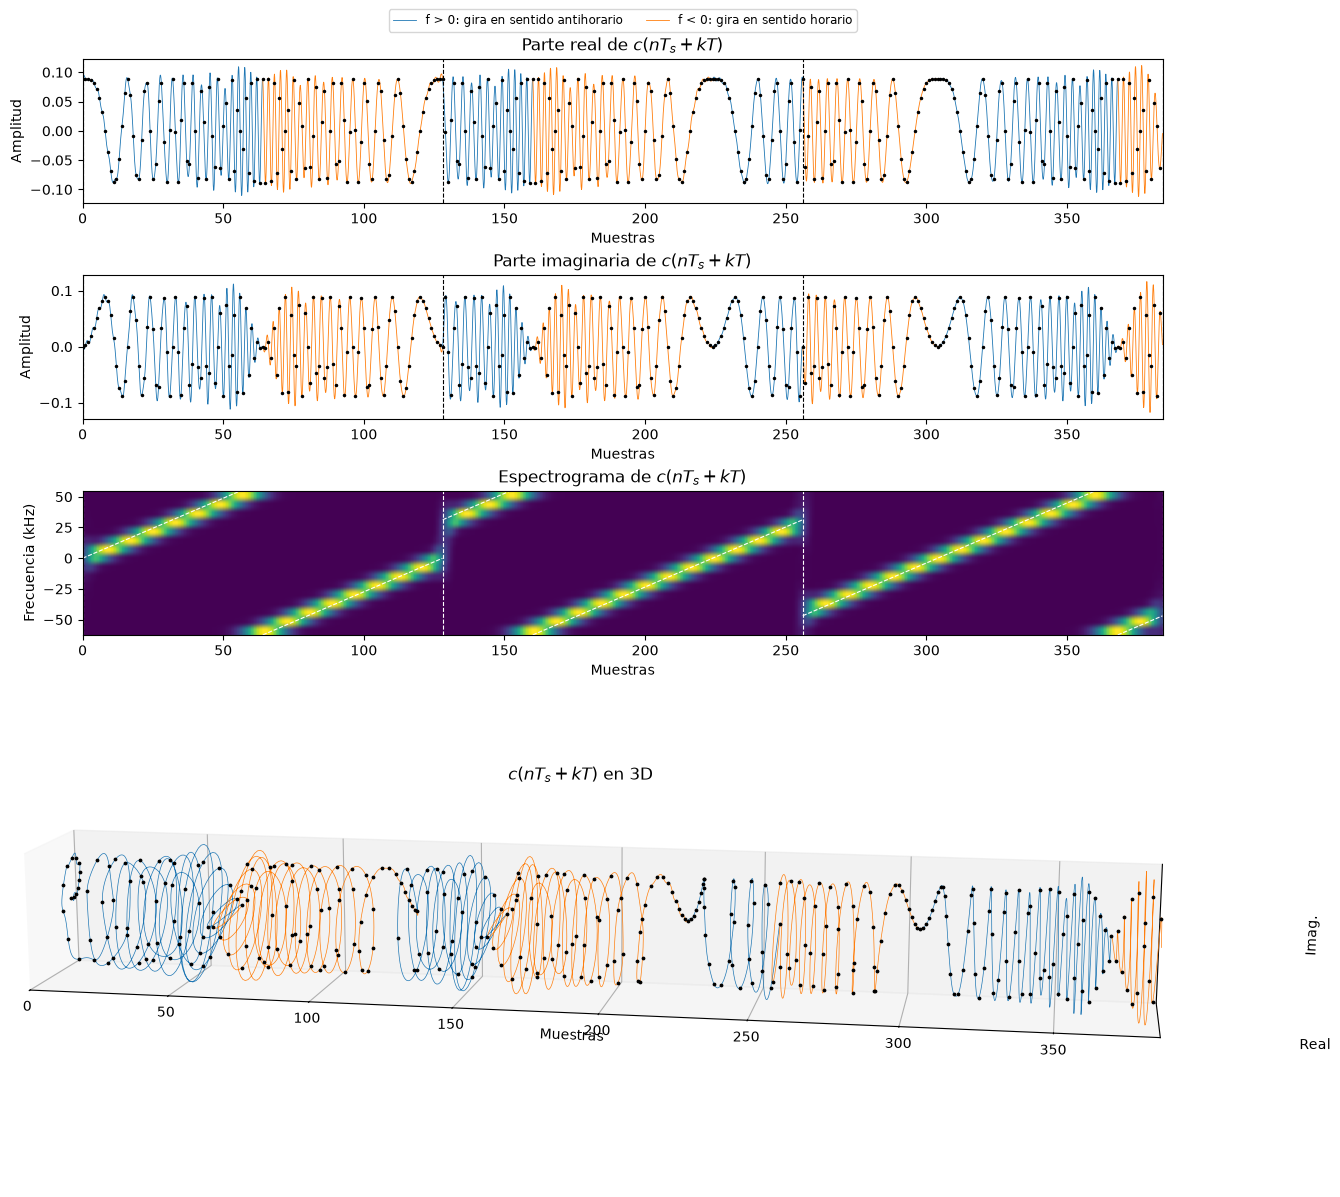

In [43]:
"""
Calcula la frecuencia instantánea de la Ec. 2, en la banda centrada.

    Parámetros:
        simbolos: Símbolos modulados.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        L: Puntos por chip.

    Devuelve:
        La frecuencia, en Hz, entre -B/2 y B/2, con L puntos por chip.
"""

def frecuencia_en_banda_centrada(simbolos: np.ndarray, SF: int, B: float, L: int) -> np.ndarray:

    N = 2**SF
    k = np.arange(N * L) / L  # Tiempo dentro del símbolo, en chips

    frecuencia = []
    for s in simbolos:
        # En la Ec. 2 la frecuencia sube de s B / 2^SF hasta B y vuelve a 0 (el mod). En la banda
        # centrada, la parte de arriba de B/2 aparece como negativa: f - B
        f = (s + k) / N % 1 * B
        frecuencia.append(np.where(f >= B / 2, f - B, f))
    return np.concatenate(frecuencia)


"""
Grafica la señal modulada: parte real, parte imaginaria, espectrograma y la señal compleja en 3D.

    Parámetros:
        simbolos: Símbolos a modular.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        L: Puntos por chip de las curvas.

    Devuelve:
        La figura.
"""

def graficar_senal_modulada(simbolos: np.ndarray, SF: int, B: float, L: int = 16):

    # Las curvas son la señal que reconstruiría un DAC ideal a partir de las muestras (los
    # puntos), con frecuencias entre -B/2 y B/2. Son azules donde la frecuencia es positiva (la
    # señal gira en sentido antihorario) y naranjas donde es negativa (sentido horario)
    N = 2**SF
    c = conformador_de_onda(simbolos, SF, B)
    t, c_fino = reconstruir_como_dac(c, L)
    f = frecuencia_en_banda_centrada(simbolos, SF, B, L)

    # Cada curva se parte en dos tramos según el signo de f. Los tramos comparten el punto donde
    # cambia el signo, para que la curva quede unida
    positiva = f >= 0
    tramos = [
        (positiva | np.roll(positiva, 1), "C0", "f > 0: gira en sentido antihorario"),
        (~positiva | np.roll(~positiva, 1), "C1", "f < 0: gira en sentido horario"),
    ]

    fig = plt.figure(figsize=(12, 12))
    ax_real = fig.add_axes((0.07, 0.8, 0.9, 0.12))
    ax_imag = fig.add_axes((0.07, 0.62, 0.9, 0.12))
    ax_espectro = fig.add_axes((0.07, 0.44, 0.9, 0.12))
    ax_3d = fig.add_axes((0, -0.02, 0.97, 0.42), projection="3d")

    # Parte real e imaginaria
    partes = [(ax_real, np.real, "Parte real"), (ax_imag, np.imag, "Parte imaginaria")]
    for ax, parte, titulo in partes:
        for tramo, color, nombre in tramos:
            ax.plot(t, np.where(tramo, parte(c_fino), np.nan), color=color, lw=0.6, label=nombre)
        ax.plot(parte(c), "k.", ms=3)
        ax.set(title=f"{titulo} de $c(nT_s + kT)$", ylabel="Amplitud")
    ax_real.legend(loc="lower center", bbox_to_anchor=(0.5, 1.15), ncol=2, fontsize="small")

    # Espectrograma de c, en la misma banda que las curvas, con la frecuencia de la Ec. 2. La
    # línea se corta en los saltos de frecuencia, para no unirlos
    graficar_espectrograma(ax_espectro, c, B)
    saltos = np.abs(np.diff(f, prepend=f[0])) > B / N
    ax_espectro.plot(t, np.where(saltos, np.nan, f) / 1e3, "w--", lw=0.8)
    ax_espectro.set_ylim(ax_espectro.images[0].get_extent()[2:])  # Solo la banda de la imagen
    ax_espectro.set_title(
        "Espectrograma de $c(nT_s + kT)$"
    )

    for ax in (ax_real, ax_imag, ax_espectro):
        ax.set(xlabel="Muestras", xlim=(0, c.size))
        marcar_limites(ax, np.arange(len(simbolos) + 1) * N)

    # Señal compleja en 3D: tiempo, parte real y parte imaginaria. Con clip_on=False, porque el
    # zoom agranda el recuadro 3D más allá de los ejes y las curvas se recortarían
    for tramo, color, _ in tramos:
        y = np.where(tramo, c_fino, np.nan)
        ax_3d.plot(t, np.real(y), np.imag(y), color=color, lw=0.5, clip_on=False)
    k = np.arange(c.size)
    ax_3d.scatter(k, np.real(c), np.imag(c), color="k", s=3, depthshade=False, clip_on=False)
    limite = 1.3 / np.sqrt(N)  # Un poco más que la amplitud del chirp
    ax_3d.set(
        xlabel="Muestras",
        ylabel="Real",
        zlabel="Imag.",
        xlim=(0, c.size),
        ylim=(-limite, limite),
        zlim=(-limite, limite),
        yticks=[],
        zticks=[],
    )
    ax_3d.set_box_aspect((8, 1, 1), zoom=2.2)  # Largo en el tiempo
    ax_3d.view_init(elev=12, azim=-80)
    ax_3d.set_title("$c(nT_s + kT)$ en 3D", y=0.86)
    return fig


graficar_senal_modulada(symbols, SF, B);

**Observaciones**:
- La parte real de $\tilde{c}$ es una onda cosenoidal cuya frecuencia crece a lo largo del símbolo, con un salto donde la frecuencia vuelve a $0$.
- El espectrograma muestra una sola pasada por la banda en cada símbolo, que empieza en $f_0 - B/2$ y por lo tanto es distinta para cada símbolo.

La Ec. 2, en cambio, multiplica $f(k)$ directamente por $kT$. La figura siguiente muestra la señal $c$ que genera el modulador según la Ec. 2, graficada de la misma forma, con la línea que evalúa la Ec. 2 también entre muestras y el espectrograma calculado sobre $c\,(-1)^k$.

## Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas. A partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ _chips_ por cada símbolo enviado, el conformador de tuplas produce el arreglo de símbolos recibidos.

Antes de presentar el método formal de demodulación, Vangelista demuestra que el espacio vectorial de las $2^{SF}$ señales que el conformador genera (una por cada posible símbolo) es un espacio vectorial ortogonal.

El método de demodulación propuesto consiste en calcular la correlación cruzada de un tramo de $2^{SF}$ _chips_ de la señal recibida, correspondiente a la transmisión de un símbolo, con cada uno de los vectores de la base de este espacio vectorial (los posibles _chirps_). Puede también interpretarse como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{s(nT_s) = q}$ entre sí.

Dada la ortogonalidad del espacio vectorial, en ausencia de ruido la única correlación distinta de cero es la que corresponde al símbolo recibido, es decir, la correlación de la señal recibida con un _chirp_ idéntico a ella, que equivale a su autocorrelación.

Sobre este método, Vangelista desarrolla una forma computacionalmente más eficiente, descrita en la Ec. 16, que calcula todas las correlaciones cruzadas a la vez:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j\pi \frac{k^2}{2^{SF}}} \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

La ecuación se puede reescribir como:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} d(nT_s + kT) \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}} = \frac{1}{\sqrt{2^{SF}}}\, \mathrm{DFT}\left\{ d(nT_s + kT) \right\}[q]
$$

donde $d(nT_s + kT)$ es una exponencial compleja de frecuencia constante, igual a la frecuencia inicial del _chirp_ recibido, cuando la señal recibida es un _chirp_ de la Ec. 2:

$$
d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j\pi \frac{k^2}{2^{SF}}} = \frac{1}{\sqrt{2^{SF}}}\, e^{j2\pi \frac{\left[(s(nT_s) + k/2) \bmod 2^{SF}\right] k}{2^{SF}}}\, e^{-j\pi \frac{k^2}{2^{SF}}} = \frac{1}{\sqrt{2^{SF}}}\, e^{j2\pi \frac{s(nT_s)\, k}{2^{SF}}}
$$

Al proceso de multiplicar la señal recibida por el término $e^{-j\pi \frac{k^2}{2^{SF}}}$, conocido como *down-chirp*, se le llama _de-chirpeado_.

Luego, el paso restante es calcular la sumatoria, que es una Transformada Discreta de Fourier (DFT) y puede computarse mediante la Transformada Rápida de Fourier (FFT). Como $d(nT_s + kT)$ es una exponencial de frecuencia constante, su espectro es un impulso en el bin $q = s(nT_s)$. El demodulador decide entonces el símbolo como el índice del bin de mayor módulo, $\hat{s}(nT_s) = \arg\max_q |\langle r, c|_{s=q} \rangle|^2$, donde $|\langle r, c|_{s=q} \rangle|^2$ es el periodograma de $d(nT_s + kT)$, es decir, una estimación de su densidad espectral de potencia.

Por el teorema de Einstein-Wiener–Khinchin, la densidad espectral de potencia de una señal es la transformada de Fourier de su autocorrelación, lo que permite ver cómo se reparten la señal y el ruido entre los $2^{SF}$ bins. La autocorrelación de una exponencial compleja es otra exponencial de la misma frecuencia, por lo que la densidad espectral de $d(nT_s + kT)$ es un impulso y toda la energía del símbolo cae en el bin $q = s(nT_s)$.

El ruido blanco, por definición, tiene una densidad espectral plana y, por lo tanto, una autocorrelación impulsiva, así que su potencia se reparte en partes iguales entre los $2^{SF}$ bins del espectro. El *down-chirp* no altera esto, porque multiplicar el ruido blanco por una exponencial de módulo 1 no cambia su autocorrelación, y su densidad espectral sigue siendo plana. El _de-chirpeado_ concentra entonces la energía del símbolo en un solo bin mientras el ruido queda repartido en todos, lo que permite decidir correctamente aun cuando la potencia del ruido supera a la de la señal (ver *Límite de decisión en un canal plano*).

Este método asume que la demodulación está sincronizada, es decir, que el receptor ya detectó la trama y conoce dónde empieza cada símbolo, por lo que puede dividir la señal en tramos de $2^{SF}$ _chips_. El proceso de detección se detalla en *Detección de una trama*.

In [44]:
"""
Multiplica cada símbolo recibido por el down-chirp.

    Parámetros:
        recibido: Señal recibida; su largo tiene que ser múltiplo de 2^SF.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        d, con una fila por símbolo y una columna por chip.
"""

def dechirpear(recibido: np.ndarray, SF: int) -> np.ndarray:

    N = 2**SF  # Chips por símbolo
    assert recibido.size % N == 0, "El número de muestras debe ser múltiplo de 2^SF"

    k = np.arange(N)
    down_chirp = np.exp(-1j * np.pi * k**2 / N)  # e^{-jπ k²/2^SF}

    # Una fila por símbolo: d[n] son los N chips del símbolo n multiplicados por el down-chirp
    d = []
    for n in range(recibido.size // N):
        chips = recibido[n * N : (n + 1) * N]
        d.append(chips * down_chirp)
    return np.array(d)


"""
Calcula <r, c|s=q> para cada símbolo recibido y cada q (Ec. 16).

    Parámetros:
        recibido: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Una fila por símbolo y una columna por q.
"""

def proyecciones(recibido: np.ndarray, SF: int) -> np.ndarray:

    # Ec. 16: <r, c|s=q> para cada símbolo n (filas) y cada q (columnas). Es la DFT de d dividida
    # por sqrt(2^SF), que es lo que calcula la FFT con norm="ortho"
    return np.fft.fft(dechirpear(recibido, SF), norm="ortho")


"""
Decide cada símbolo recibido como el q de mayor |<r, c|s=q>|^2.

    Parámetros:
        recibido: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Los símbolos decididos.
"""

def demodulador(recibido: np.ndarray, SF: int) -> np.ndarray:

    # Decide cada símbolo como el q de mayor |<r, c|s=q>|^2, el periodograma de d
    periodograma = np.abs(proyecciones(recibido, SF)) ** 2
    return np.argmax(periodograma, axis=1)

### Decodificación

Una vez generados por el conformador de tuplas, los símbolos recibidos son procesados por el decodificador, que descompone cada uno en un arreglo de $SF$ bits de acuerdo a la Ec. 1, el proceso inverso al descrito en *Codificador*.

In [45]:
"""
Convierte símbolos en bits: el proceso inverso de la Ec. 1.

    Parámetros:
        simbolos: Símbolos recibidos.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        SF bits por símbolo, del menos significativo al más significativo.
"""

def decodificador(simbolos: np.ndarray, SF: int) -> np.ndarray:

    bits = []
    for s in simbolos:
        # Inverso de la Ec. 1: el bit h de s es el resto de dividir s // 2^h por 2
        for h in range(SF):
            bits.append((s // 2**h) % 2)
    return np.array(bits)

#### Visualización del proceso de decisión

##### Recepción sin ruido

Se sigue paso a paso la demodulación de un único símbolo para visualizar cómo el *down-chirp* y la FFT transforman la señal recibida utilizando $SF = 6$, con $2^{SF} = 64$ muestras por símbolo, y $B = 125$ kHz. Se elige el símbolo $s = 20$, distinto de 0 para que $d(nT_s + kT)$ oscile y el impulso no caiga en el bin 0. La figura muestra, de arriba hacia abajo:

1. La parte real de la señal recibida $r(nT_s + kT)$, un *chirp* de la Ec. 2.
2. El espectrograma de $r$ centrado en la banda $B$.
3. La parte real de la señal de-chirpeada $d(nT_s + kT)$, que según *Demodulación* es una exponencial de frecuencia constante igual a $s$ oscilaciones por cada longitud $2^{SF}$ de símbolo.
4. El periodograma $|\langle r, c|_{s=q} \rangle|^2$ que calcula el demodulador, es decir, la estimación de la densidad espectral de potencia de $d$. El bin del símbolo transmitido se resalta en rojo y el del símbolo decidido $\hat{s}$ en azul, o en violeta cuando coinciden.

En los gráficos de la parte real la curva evalúa la señal sin ruido entre muestras para visualizar la forma de la onda sin aliasing. Los puntos son las muestras con las que trabaja el receptor.

<!-- TODO(b-Tomas): si Ayarde nos da el OK, usar la fórmula arreglada y sacar la nota del aliasing. Si no, quitar totalemente el primer gráfico -->

In [46]:
"""
Grafica la demodulación de un símbolo: r, su espectrograma, d y el periodograma.

    Parámetros:
        r: Un símbolo recibido, de 2^SF muestras.
        s: Símbolo transmitido.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR del canal para el título, o None.
        h: Respuesta al impulso del canal; None es el canal plano.

    Devuelve:
        La figura.
"""

def graficar_demodulacion(
    r: np.ndarray,
    s: int,
    SF: int,
    B: float,
    SNR_dB: float | None = None,
    h: np.ndarray | None = None,
):

    # Demodulación de un símbolo recibido r, paso a paso: r, su espectrograma, d y el periodograma
    # de d. De r y d se grafican la parte real y la imaginaria, con la curva que reconstruiría un
    # DAC ideal a partir de las muestras. h es la respuesta al impulso del canal, para el gráfico
    # de la amplitud de cada camino
    N = 2**SF
    if h is None:
        h = np.array([1.0])  # Canal plano: un solo camino, sin atenuación
    d = dechirpear(r, SF)[0]

    # Con eco se agrega, después de r, un gráfico de la amplitud de cada camino
    hay_eco = len(h) > 1
    n_graficos = 6 + hay_eco
    fig, axs = plt.subplots(n_graficos, 1, figsize=(10, 2.5 * n_graficos))
    ax_r_real, ax_r_imag = axs[0], axs[1]
    ax_espectro, ax_d_real, ax_d_imag, ax_P = axs[-4], axs[-3], axs[-2], axs[-1]

    graficar_real_e_imaginaria(ax_r_real, ax_r_imag, r, "$r(nT_s + kT)$")

    if hay_eco:
        ax_amp = axs[2]
        ax_amp.plot(np.abs(r), lw=0.8, label="$|r|$")
        ax_amp.plot(np.abs(r), "k.", ms=3)
        for i, h_i in enumerate(h):
            nombre = "Camino directo" if i == 0 else "Eco"
            ax_amp.axhline(abs(h_i) / np.sqrt(N), color=f"C{i + 2}", ls="--", lw=1.2, label=nombre)
        # Lugar arriba de la curva para la leyenda
        ax_amp.set(
            title="Amplitud de $r(nT_s + kT)$ y de cada camino del canal",
            ylabel="Amplitud",
            ylim=(0, 1.35 * np.abs(h).sum() / np.sqrt(N)),
        )
        ax_amp.legend(loc="upper center", ncol=3, fontsize="small")

    # Espectrograma de r en la banda centrada, de -B/2 a B/2, la misma que la de las curvas
    graficar_espectrograma(ax_espectro, r, B)
    ax_espectro.set_title("Espectrograma de $r(nT_s + kT)$ en la banda centrada")

    graficar_real_e_imaginaria(ax_d_real, ax_d_imag, d, "$d(nT_s + kT)$")

    for ax in axs[:-1]:
        ax.set(xlabel="Muestras", xlim=(0, N))

    P = np.abs(proyecciones(r, SF)[0]) ** 2
    s_decidido = graficar_periodograma(ax_P, P, s, SF, B)
    ax_P.set_title(
        rf"Periodograma de $d$, $|\langle r, c|_{{s=q}} \rangle|^2$ (decidido ŝ={s_decidido})"
    )

    titulo = f"Símbolo transmitido s={s}"
    if SNR_dB is not None:
        titulo += f", SNR={SNR_dB} dB"
    fig.suptitle(titulo)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.3 / fig.get_figheight()))  # Lugar para el título
    return fig

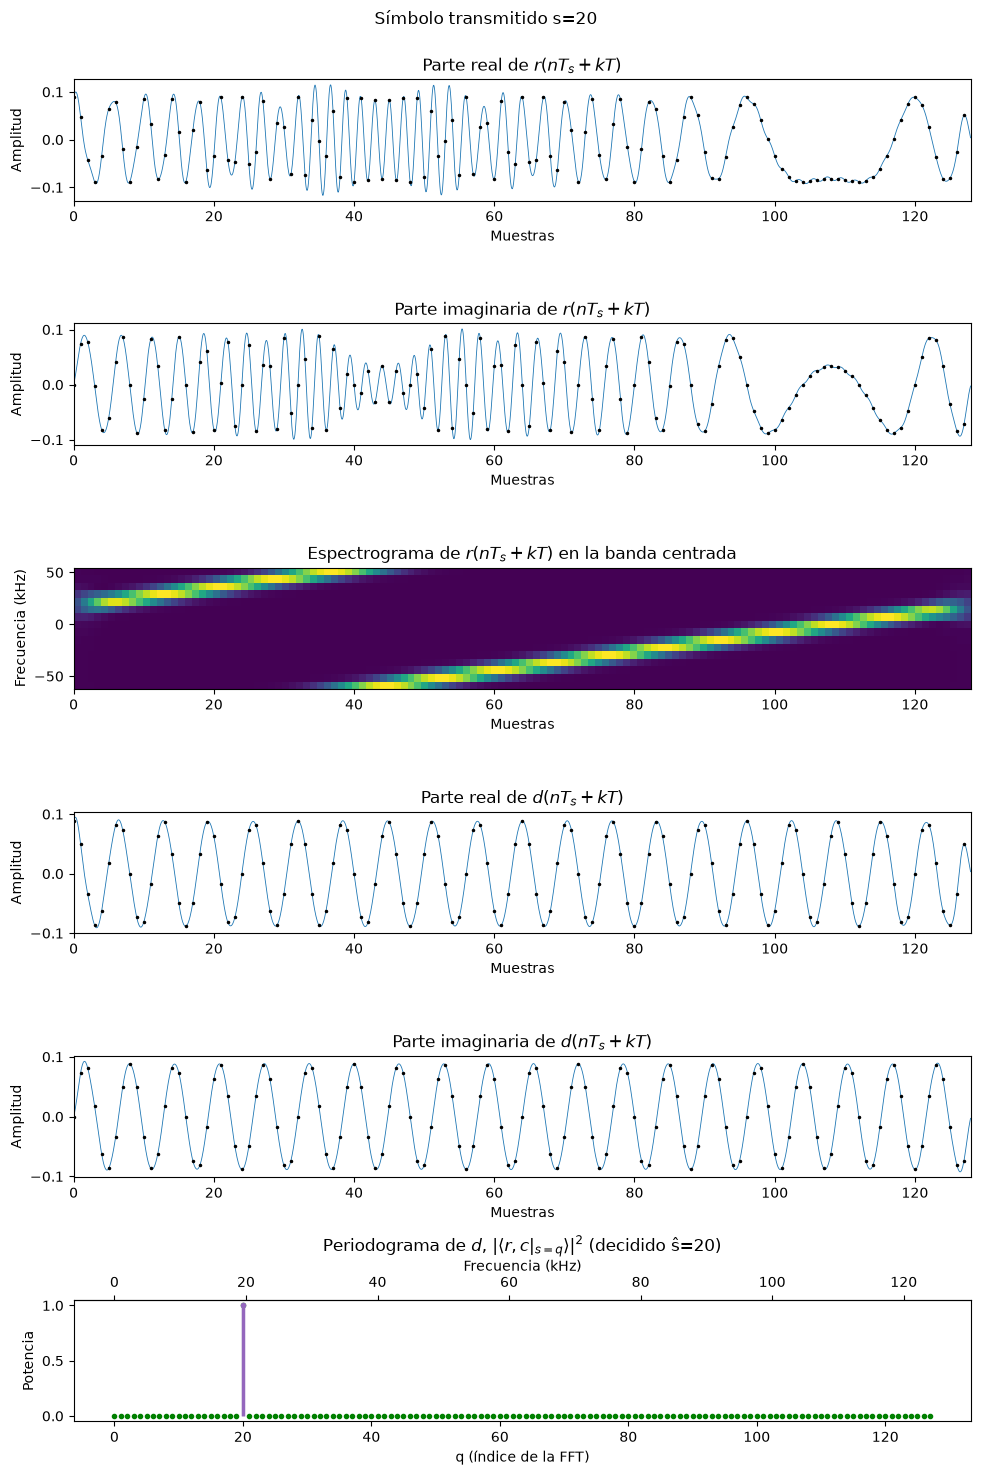

In [47]:
# Demodulación paso a paso de un símbolo sin ruido
SFD = 7
s = 20
c_s = conformador_de_onda(np.array([s]), SFD, B)

graficar_demodulacion(c_s, s, SFD, B);

**Observaciones**:
- La parte real de $r$ no muestra lo que se espera por la descripción del paper (ver *Análisis de la señal modulada*), un *chirp* cuya frecuencia sube hasta $B$ y vuelve a 0 en $k = 2^{SF} - s = 60$. La frecuencia de la curva sube sin cortes hasta casi $2B$, porque la fase de la Ec. 2 crece con $k^2$. El $\bmod$ de la Ec. 2 no aparece porque en cada muestra resta un número entero de ciclos de fase, así que no cambia las muestras, y la curva se dibuja sin él. <!-- TODO(b-Tomas): si Ayarde nos da el OK, usar la fórmula arreglada. Si no, considerar quitar totalmente esta nota -->
- Después del *down-chirp*, $d$ es una sinusoide de 20 ciclos por símbolo, de frecuencia $20\, B / 2^{SF} \approx 39$ kHz.
- El periodograma es un impulso de valor 1 en $q = 20$, es decir, toda la energía del símbolo cae en un solo bin, como corresponde a la densidad espectral de una exponencial de frecuencia constante.

##### Recepción con ruido

Se repite el mismo símbolo sumándole ruido blanco gaussiano aditivo (AWGN) con un SNR de -3 dB, es decir, con el doble de la potencia de la señal ($10^{-3/10} \approx 0.50$).

In [48]:
# Ruido blanco gaussiano aditivo (AWGN). El modelo del ruido y la definición del SNR se explican en
# *Modelo de canal ruidoso*


"""
Potencia de una señal: el valor medio del módulo al cuadrado.

    Parámetros:
        x: Señal.

    Devuelve:
        La potencia.
"""

def potencia(x: np.ndarray) -> float:

    # Valor medio del módulo al cuadrado de las muestras
    return float(np.mean(np.abs(x) ** 2))


"""
Genera ruido blanco gaussiano complejo con el SNR pedido respecto de c.

    Parámetros:
        c: Señal de referencia; el ruido tiene su misma forma.
        SNR_dB: SNR, en dB.

    Devuelve:
        El ruido.
"""

def ruido_awgn(c: np.ndarray, SNR_dB: float) -> np.ndarray:

    # Ruido gaussiano complejo con el SNR pedido respecto de la potencia de c
    SNR = 10 ** (SNR_dB / 10)
    varianza = potencia(c) / SNR  # sigma_w^2

    # Parte real e imaginaria independientes, cada una con la mitad de la varianza
    sigma = np.sqrt(varianza / 2)
    return rng.normal(0, sigma, c.shape) + 1j * rng.normal(0, sigma, c.shape)  ## @SHAPE: dimension de c

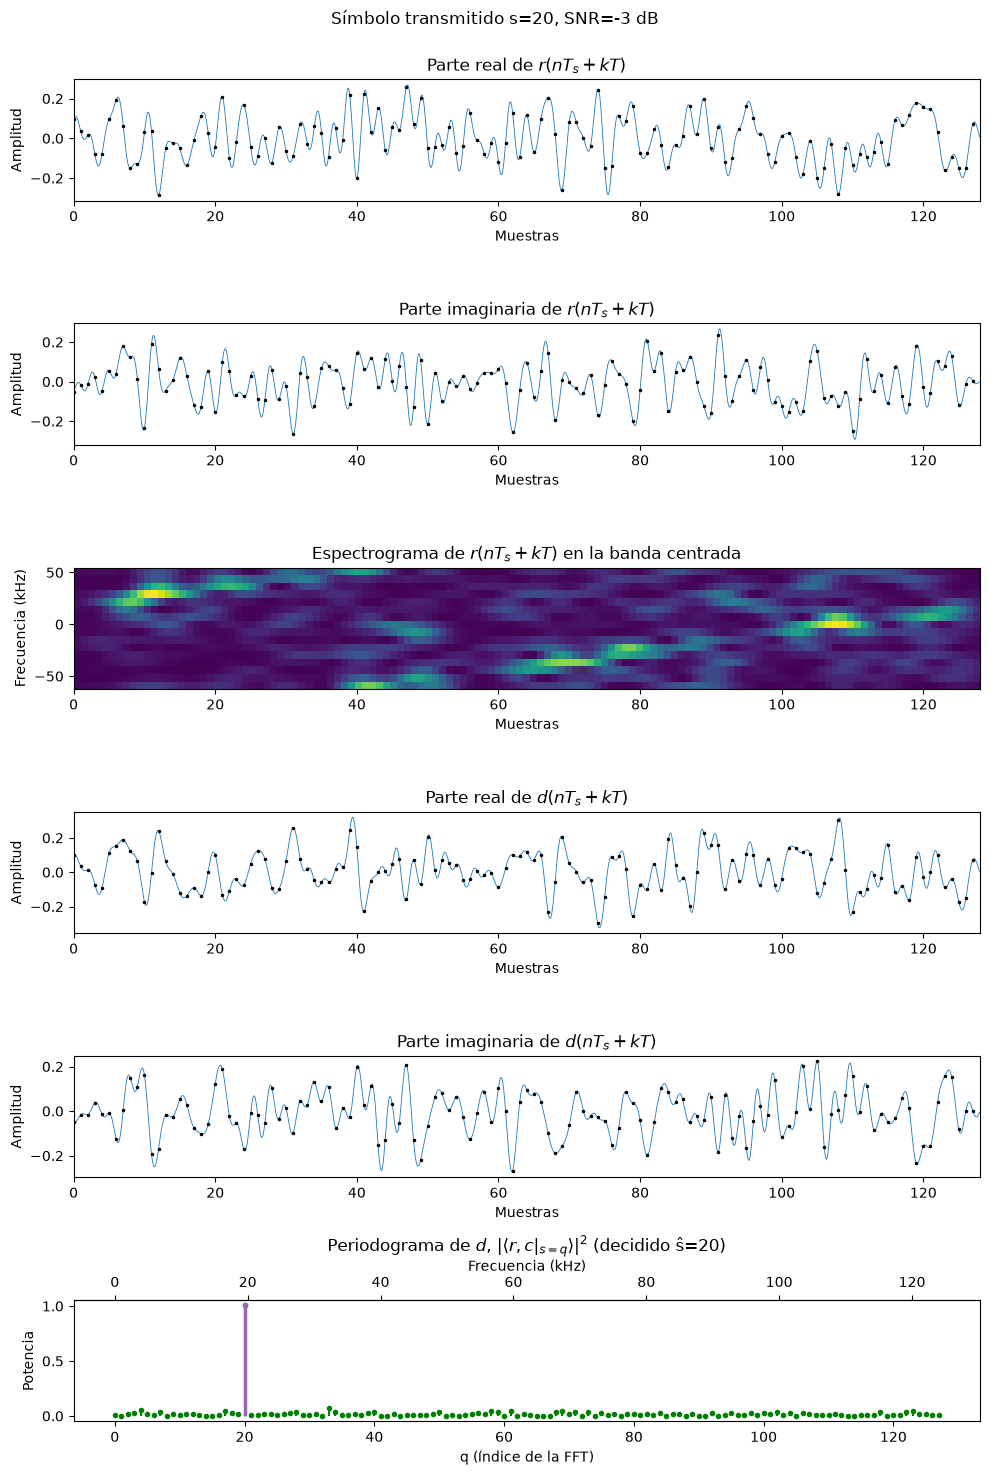

In [49]:
# Demodulación paso a paso del mismo símbolo con ruido
SNR_dB = -3
r = c_s + ruido_awgn(c_s, SNR_dB)  # Canal plano: solo se suma el ruido

graficar_demodulacion(r, s, SFD, B, SNR_dB)

# Reiniciar la semilla para no alterar los valores aleatorios de las secciones siguientes
rng = np.random.default_rng(0)

**Observaciones**:
- Las muestras de $r$ se apartan de la curva sin ruido y el *chirp* casi no se reconoce en la parte real.
- El espectrograma todavía muestra sus dos pasadas por la banda, aunque con considerablemente menos nitidez.
- En $d$ la sinusoide de 20 ciclos se sigue distinguiendo entre la dispersión de las muestras.
- La energía del símbolo queda concentrada en $q = 20$, marcando un máximo considerablemente por encima de los demás bins donde se observa el ruido, y la decisión es correcta.

## Modelo de canal ruidoso

Un canal introduce dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y retardos. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido. Se considera que el ruido será blanco gaussiano aditivo (AWGN) al simular la transmisión.

La señal recibida es $r = c * h + w$

TODO(b-Tomas): gráfico de bloques de un canal ruidoso

### Cálculo del Bit Error Rate (BER)

Para medir el desempeño de la modulación/demodulación en un canal se utiliza el BER.

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

$$
BER = \frac{\text{cantidad de bits erróneos}}{\text{cantidad de bits transmitidos}}
$$

A continuación se simula una transmisión de $100$ símbolos con $SF=7$ (para un total de $7*100=700$ bits) en un canal ideal sin ruido, con un bit erróneo:

In [13]:
"""
Fracción de bits recibidos distintos de los transmitidos.

    Parámetros:
        bits_tx: Bits transmitidos.
        bits_rx: Bits recibidos, del mismo largo.

    Devuelve:
        El BER.
"""

def BER(bits_tx: np.ndarray, bits_rx: np.ndarray) -> float:

    assert bits_tx.size == bits_rx.size, "Los conjuntos de bits deben tener la misma longitud"
    errores = np.sum(bits_tx != bits_rx)  # Bits recibidos distintos de los transmitidos
    return errores / bits_tx.size


# Simular una transmisión completa de 100 símbolos aleatorios, sin ruido
bits_tx = rng.integers(0, 2, size=SF * 100)
senal = conformador_de_onda(codificador(bits_tx, SF), SF, B)
bits_rx = decodificador(demodulador(senal, SF), SF)
print(f"Bit Error Rate (BER): {BER(bits_tx, bits_rx):.4f}")

# En caso de corromper un bit:
bits_rx[0] ^= 1  # bit flip
print(f"Bit Error Rate (BER) con un bit corrupto: {BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


### Potencia de la señal modulada

La potencia de una señal discreta es el valor medio del módulo al cuadrado de sus muestras. Todas las muestras de la Ec. 2 tienen módulo $1/\sqrt{2^{SF}}$, así que cada símbolo de $2^{SF}$ muestras tiene energía 1 y la potencia de la señal modulada es

$$
P_c = \frac{1}{2^{SF}}
$$

para cualquier símbolo. La celda siguiente la calcula con $SF = 7$ y con $SF = 2$.

In [14]:
for sf in [7, 2]:
    P = potencia(conformador_de_onda(np.array([0]), sf, B))
    print(f"Potencia de la señal modulada con SF={sf}, B={B / 1e3:.0f} kHz: {P:.4f}")

Potencia de la señal modulada con SF=7, B=125 kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125 kHz: 0.2500


**Observaciones**:
- La potencia coincide con $1/2^{SF}$, $1/128 \approx 0.0078$ con $SF = 7$ y $1/4 = 0.25$ con $SF = 2$.

### Relación señal-ruido (SNR)

El ruido $w$ de la Ec. 10 es gaussiano complejo, de media nula y con la misma varianza $\sigma_w^2$ en todas las muestras. La relación señal-ruido (SNR) se define por muestra como el cociente entre la potencia de la señal y la del ruido:

$$
SNR = \frac{P_c}{\sigma_w^2}, \qquad SNR_{dB} = 10 \log_{10} SNR
$$

Para simular un SNR dado, primero se calcula la potencia de la señal transmitida $P_c$, que depende de $SF$, y con ella la varianza del ruido, $\sigma_w^2 = P_c / SNR$. Después se generan la parte real y la imaginaria del ruido como dos variables gaussianas independientes, cada una con varianza $\sigma_w^2 / 2$, para que la potencia total del ruido sea $\sigma_w^2$. Un SNR negativo en dB significa que el ruido tiene más potencia que la señal.

A continuación se genera ruido con un SNR de $-10$ dB sobre una señal de tres símbolos y se mide el SNR que resulta de la simulación.

In [15]:
# Guardar el estado del generador para no alterar los valores aleatorios de las secciones siguientes
estado = rng.bit_generator.state

# Ruido con SNR de -10 dB sobre la señal de los tres símbolos
SNR_dB = -10
z = ruido_awgn(c, SNR_dB)
rng.bit_generator.state = estado

SNR_medido_dB = 10 * np.log10(potencia(c) / potencia(z))
print(f"Potencia de la señal: {potencia(c):.4f}, potencia del ruido: {potencia(z):.4f}")
print(f"SNR pedido: {SNR_dB} dB, SNR medido: {SNR_medido_dB:.2f} dB")

Potencia de la señal: 0.0078, potencia del ruido: 0.0743
SNR pedido: -10 dB, SNR medido: -9.78 dB


**Observaciones**:
- La potencia del ruido, 0.0743, es unas 10 veces la de la señal, 0.0078.
- El SNR medido es de $-9.78$ dB y no exactamente $-10$ dB, porque la potencia medida en las 384 muestras de ruido fluctúa $\sigma_w^2$.

### Transmisión en canal ruidoso

Se repite la transmisión de 100 símbolos ($SF=7$, $700$ bits) realizada anteriormente con un SNR de $-10$ dB en un canal ideal.

In [16]:
CANAL_PLANO = np.array([1.0])  # h[n] = δ[n]: el canal no distorsiona la señal, solo se suma ruido


"""
Pasa la señal por el canal: r = c * h + w.

    Parámetros:
        c: Señal transmitida.
        h: Respuesta al impulso del canal.
        w: Ruido, del largo de c, o 0 para un canal sin ruido.

    Devuelve:
        La señal recibida, del mismo largo que c.
"""

def canal(c: np.ndarray, h: np.ndarray, w: np.ndarray | float) -> np.ndarray:

    # r = c * h + w: convolución con la respuesta al impulso del canal, más el ruido.
    # mode="same" deja r del mismo largo que c
    return np.convolve(c, h, mode="same") + w


"""
Calcula una sola vez, con conformador_de_onda, el chirp de cada símbolo.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Lista con el chirp de cada símbolo q = 0, ..., 2^SF - 1.
"""

@cache
def tabla_de_chirps(SF: int, B: float) -> list[np.ndarray]:

    # El chirp de cada uno de los 2^SF símbolos, calculado con el conformador de onda una sola vez
    # por cada SF y B (@cache guarda el resultado). Las simulaciones transmiten miles de símbolos:
    # concatenar estos chirps da la misma señal que conformador_de_onda, mucho más rápido
    return [conformador_de_onda(np.array([q]), SF, B) for q in range(2**SF)]


"""
Transmite bits aleatorios por un canal con ruido y calcula el BER.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.
        h: Respuesta al impulso del canal.
        n_simbolos: Símbolos transmitidos.

    Devuelve:
        El BER de la transmisión.
"""

def ber_de_transmision(
    SF: int, B: float, SNR_dB: float, h: np.ndarray, n_simbolos: int = 100
) -> float:

    # Transmite n_simbolos símbolos de bits aleatorios por el canal h con ruido y calcula el BER
    chirps = tabla_de_chirps(SF, B)
    bits_tx = rng.integers(0, 2, size=SF * n_simbolos)
    c = np.concatenate([chirps[s] for s in codificador(bits_tx, SF)])
    r = canal(c, h, ruido_awgn(c, SNR_dB))
    bits_rx = decodificador(demodulador(r, SF), SF)
    return BER(bits_tx, bits_rx)


# Transmisión de 100 símbolos aleatorios por un canal plano
SNR_dB = -10
ber = ber_de_transmision(SF, B, SNR_dB, CANAL_PLANO)
print(f"Bit Error Rate (BER) con SNR={SNR_dB}dB: {ber:.4f}")

Bit Error Rate (BER) con SNR=-10dB: 0.0157


**Observaciones**:
- Aun con un ruido 10 veces más potente que la señal, solo 1 de los 700 bits es erróneo (BER $\approx 0.0014$), porque el *de-chirpeado* concentra la energía del símbolo en un bin mientras el ruido se reparte entre los $2^{SF}$ bins.

### Límite de decisión en un canal plano

Un canal es plano cuando su respuesta en frecuencia es constante en toda la banda de la señal, de modo que todas las frecuencias del *chirp* llegan con la misma ganancia y el mismo retardo y la forma de la señal no cambia. En el modelo $r = c * h + w$ corresponde a $h[n] = \delta[n]$, y la señal recibida es efectivamente la señal transmitida más el ruido, $r = c + w$.

TODO(b-Tomas): agregar un gráfico

Se baja el SNR a $-15$ dB para obsrevar cómo empieza a fallar la decisión. La figura muestra el periodograma de los símbolos 0, 32 y 80, con el bin del símbolo transmitido en rojo y el del símbolo decidido en azul, o en violeta cuando coinciden.

In [17]:
"""
Grafica el periodograma de cada símbolo recibido, con una columna por canal.

    Parámetros:
        D: Proyecciones <r, c|s=q> de cada símbolo, por nombre del canal.
        simbolos_tx: Símbolos transmitidos.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR del canal para el título, o None.

    Devuelve:
        La figura.
"""

def graficar_decision(
    D: dict[str, np.ndarray],
    simbolos_tx: np.ndarray,
    SF: int,
    B: float,
    SNR_dB: float | None = None,
):

    # Periodograma de cada símbolo recibido, como en graficar_demodulacion, con una columna por
    # canal. D tiene, por nombre del canal, las proyecciones <r, c|s=q> de cada símbolo
    n_filas, n_columnas = len(simbolos_tx), len(D)
    ancho = 10 if n_columnas == 1 else 7 * n_columnas

    # Misma escala en cada fila para comparar los canales
    fig, axs = plt.subplots(
        n_filas, n_columnas, figsize=(ancho, 3 * n_filas), squeeze=False, sharey="row"
    )
    for j, (nombre, proyecciones_canal) in enumerate(D.items()):
        for i, s in enumerate(simbolos_tx):
            P = np.abs(proyecciones_canal[i]) ** 2
            s_decidido = graficar_periodograma(axs[i, j], P, s, SF, B)
            axs[i, j].set_title(
                f"{nombre}, símbolo n={i}: transmitido s={s}, decidido ŝ={s_decidido}"
            )

    if SNR_dB is not None:
        fig.suptitle(f"SNR={SNR_dB} dB")
    fig.tight_layout()
    return fig

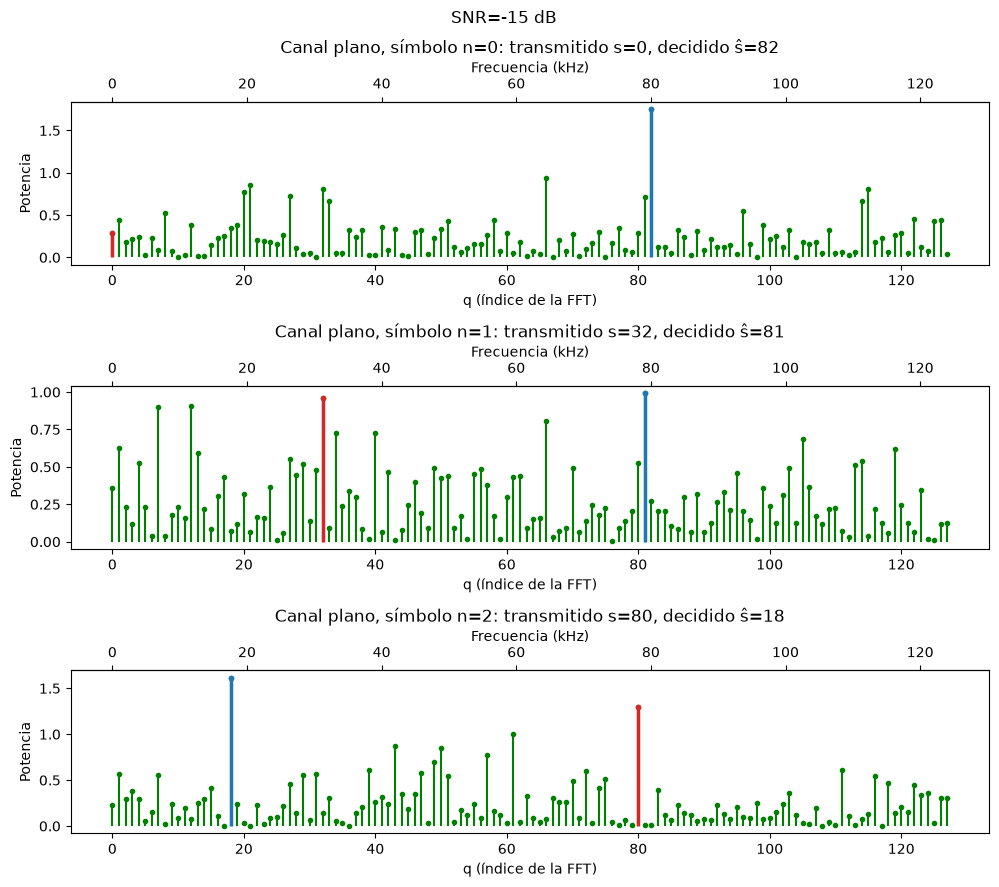

In [18]:
# Los tres símbolos con un SNR de -15 dB
SNR_dB = -15
c = conformador_de_onda(symbols, SF, B)
w = ruido_awgn(c, SNR_dB)
r = canal(c, CANAL_PLANO, w)

graficar_decision({"Canal plano": proyecciones(r, SF)}, symbols, SF, B, SNR_dB);

**Observaciones**:
- A $-15$ dB el ruido tiene 32 veces la potencia de la señal.
- El ruido se suma con fase arbitraria al bin del símbolo y puede reducirlo, como en el símbolo 0, donde baja a 0.56, o un bin de solo ruido puede superarlo, como en el símbolo 1. Solo el símbolo 80 se decidió correctamente.

### Canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia o multicaminos. La respuesta al impulso del sistema usado por Vangelista para medir el rendimiento del demodulador es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$

Cada *chirp* recibido es la suma del *chirp* transmitido con amplitud $\sqrt{0.8}$ y de un eco retrasado una muestra, con amplitud $\sqrt{0.2}$.

#### Recepción sin ruido

Se repite, a través de este canal y sin ruido, la demodulación paso a paso del símbolo $s = 20$ con $SF = 6$. Respecto de la figura del canal plano se agrega, debajo de $r$, un gráfico de la amplitud $|r|$ junto con la amplitud constante de cada camino, $\sqrt{0.8}/\sqrt{2^{SF}} \approx 0.112$ para el directo y $\sqrt{0.2}/\sqrt{2^{SF}} \approx 0.056$ para el eco.

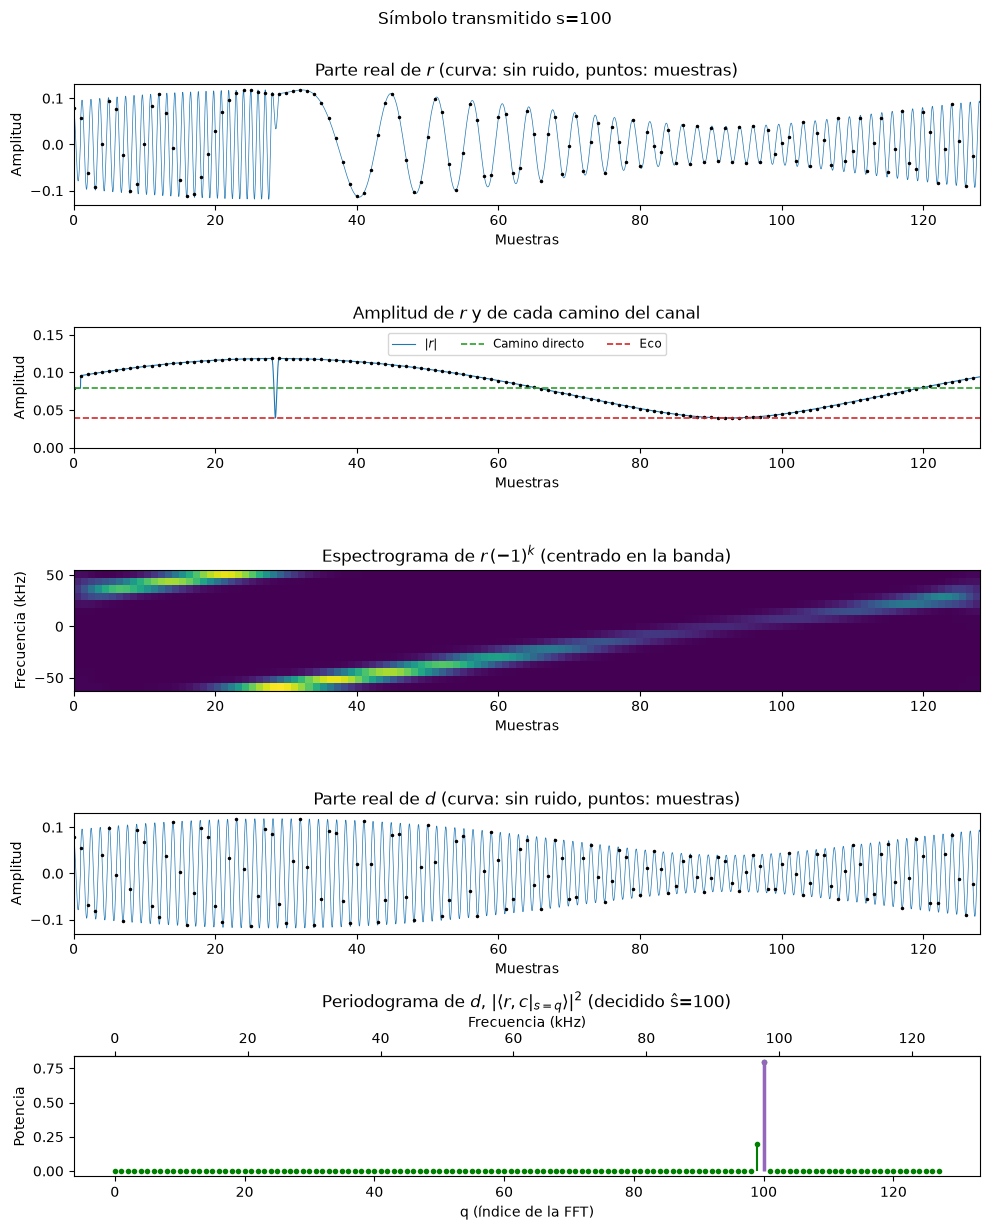

In [18]:
# Canal selectivo en frecuencia: h[n] = sqrt(0.8) δ[n] + sqrt(0.2) δ[n-1]
CANAL_SELECTIVO = np.array([np.sqrt(0.8), np.sqrt(0.2)])

# Demodulación paso a paso del mismo símbolo por el canal selectivo en frecuencia, sin ruido
r = canal(c_s, CANAL_SELECTIVO, 0)

graficar_demodulacion(r, s, SFD, B, h=CANAL_SELECTIVO);

**Observaciones**:
- $d$ ya no es una exponencial de amplitud constante, sino la suma de dos, la del camino directo con 20 ciclos por símbolo y la del eco con 18. Su amplitud oscila dos veces por símbolo, la diferencia entre ambas.
- La decisión es correcta, pero el bin del símbolo tiene un 20 % menos de potencia que en el canal plano.

#### Límite de decisión

Se repite en este canal el ensayo de *Límite de decisión en un canal plano*. Los símbolos 0, 32 y 80 se transmiten por los dos canales con el mismo ruido de esa sección, escalado a un SNR de $-10$ dB, para que la única diferencia entre ambos sea el canal. La figura muestra el periodograma de cada símbolo, con el canal plano a la izquierda y el selectivo a la derecha, y la misma escala vertical en cada fila.

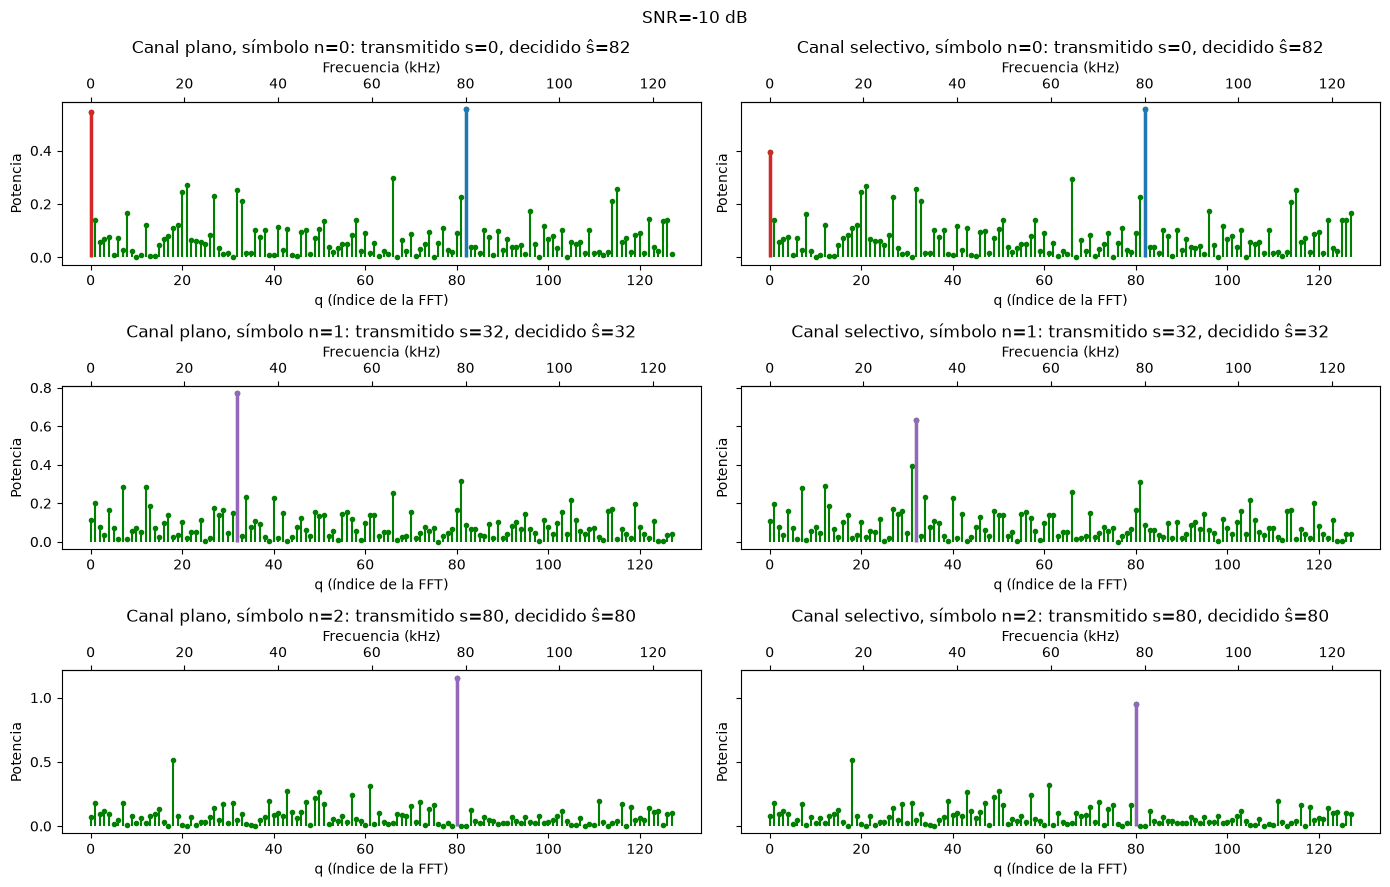

In [20]:
# Mismo ruido de la celda del canal plano, con 5 dB menos de potencia: de -15 a -10 dB
SNR_dB = -10
w_10 = w * 10 ** (-5 / 20)
D = {
    "Canal plano": proyecciones(canal(c, CANAL_PLANO, w_10), SF),
    "Canal selectivo": proyecciones(canal(c, CANAL_SELECTIVO, w_10), SF),
}

graficar_decision(D, symbols, SF, B, SNR_dB);

**Observaciones**:
- En el canal plano los tres símbolos se deciden correctamente, y en el selectivo falla el símbolo 0. Su bin queda en 0.56 y lo supera un bin de solo ruido de 0.65 en $q = 103$.
- El canal deja solo el 80 % de la potencia del símbolo en su bin y lleva el resto al bin del eco, $q = 126$ para $s = 0$, así que a un bin de ruido le alcanza con menos para superarlo.

### BER en función del SNR

Se analiza el BER vs SNR para el sistema simulado, el cual corresponde a la curva "Flat FSCM" de Fig. 1.

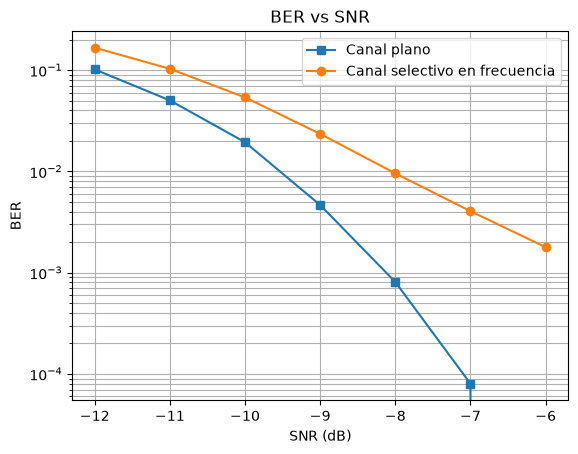

In [21]:
"""
Calcula el BER promedio para cada SNR.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNRs_dB: SNR a simular, en dB.
        h: Respuesta al impulso del canal.
        simulaciones: Transmisiones por SNR.
        n_simbolos: Símbolos por transmisión.

    Devuelve:
        El BER de cada SNR.
"""

def ber_vs_snr(
    SF: int,
    B: float,
    SNRs_dB: np.ndarray,
    h: np.ndarray,
    simulaciones: int,
    n_simbolos: int = 100,
) -> np.ndarray:

    # BER promedio de `simulaciones` transmisiones para cada SNR
    bers = []
    for SNR_dB in SNRs_dB:
        total = 0
        for _ in range(simulaciones):
            total += ber_de_transmision(SF, B, SNR_dB, h, n_simbolos)
        bers.append(total / simulaciones)
    return np.array(bers)


"""
Grafica el BER vs SNR, una curva por canal.

    Parámetros:
        SNRs_dB: SNR simulados, en dB.
        bers: BER de cada SNR, por nombre del canal.

    Devuelve:
        La figura.
"""

def graficar_ber_vs_snr(SNRs_dB: np.ndarray, bers: dict[str, np.ndarray]):

    # Una curva de BER vs SNR por canal
    fig, ax = plt.subplots()
    for (nombre, ber), marcador in zip(bers.items(), ["s", "o", "^", "d"]):
        ax.semilogy(SNRs_dB, ber, marker=marcador, label=nombre)
    ax.set(title="BER vs SNR", xlabel="SNR (dB)", ylabel="BER")
    ax.grid(True, which="both")
    ax.legend()
    return fig


SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -6 dB
simulaciones = 500  # Transmisiones de 100 símbolos por SNR

bers = {
    "Canal plano": ber_vs_snr(SF, B, SNRs_dB, CANAL_PLANO, simulaciones),
    "Canal selectivo en frecuencia": ber_vs_snr(SF, B, SNRs_dB, CANAL_SELECTIVO, simulaciones),
}
graficar_ber_vs_snr(SNRs_dB, bers);

**Observaciones**:
- En el canal plano el BER cae de $0.1$ a $4 \cdot 10^{-5}$ entre $-12$ y $-7$ dB.
- El canal selectivo en frecuencia necesita más SNR para el mismo BER, y la diferencia crece con el SNR. El eco no se comporta como ruido, porque después del *down-chirp* concentra el 20 % de la potencia en el bin $s - 2$, un competidor fijo del bin del símbolo, y al ruido le alcanza con acercar esos dos bins en lugar de levantar un bin vacío.

## Detección de una trama

En esta sección se analiza el problema de detectar una trama en un canal ruidoso del lado del receptor: decidir si llegó una trama y en qué muestra empieza (sincronización). La trama es un preámbulo de 8 *up-chirps* (símbolos 0) y 2.25 *down-chirps*, seguido del *payload*. Antes de la trama el receptor solo recibe ruido, y no sabe cuándo empieza.

Se plantean tres métodos:

1. **Correlación con el preámbulo completo** (tiempo): filtro adaptado con los 8 *up-chirps*, integración coherente.
2. **Búsqueda de 8 picos** (tiempo): correlación móvil con un solo *up-chirp*, sumando la energía de 8 picos separados un símbolo. Integración no coherente.
3. **Demodulación del preámbulo** (frecuencia): se demodula cada ventana y se cuentan las decididas como símbolo 0.

Para cada método se presenta el estadístico, su umbral de Neyman-Pearson y su aplicación a una trama de ejemplo. Al final se comparan los tres métodos con el *Frame Error Rate* (FER) y la curva ROC.

### Escenario y herramientas comunes

**Parámetros**: desde acá se usa $SF = 8$ y un *payload* de 10 símbolos. Con $SF = 8$ cada símbolo tiene el doble de muestras que con $SF = 7$ y, a igual SNR por muestra, 3 dB más de energía. El receptor escucha 5 símbolos de solo ruido antes de la trama. Cada método se aplica primero a una trama de ejemplo en el canal plano a $-10$ dB, y después se evalúa en función del SNR en el canal plano y en el selectivo en frecuencia.

**Umbral**: los tres métodos fijan el umbral con el criterio de Neyman-Pearson para la misma probabilidad de falsa alarma por símbolo, $P_{FA}$. Su valor sale de la tasa de falsas alarmas que tolera el receptor, porque cada falsa alarma hace que intente demodular una trama que no existe y, mientras tanto, puede perder una real. El receptor evalúa $B / 2^{SF}$ símbolos por segundo, así que para tolerar $R_{FA}$ falsas alarmas por segundo

$$
P_{FA} = R_{FA}\, \frac{2^{SF}}{B}
$$

Con una falsa alarma por minuto, $R_{FA} = 1/60\ \text{s}^{-1}$, resulta $P_{FA} \approx 3.4 \cdot 10^{-5}$ por símbolo. Se asume que el receptor conoce la potencia del ruido $\sigma^2$, que en la práctica se estima mientras no hay señal.

In [ ]:
# Parámetros de la trama
N_UPCHIRPS = 8  # Up-chirps (símbolos 0) del preámbulo
N_DOWNCHIRPS = 2.25  # Down-chirps del preámbulo, que marcan su fin


"""
Genera el preámbulo: N_UPCHIRPS up-chirps seguidos de N_DOWNCHIRPS down-chirps.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Las muestras del preámbulo.
"""

def preambulo(SF: int, B: float) -> np.ndarray:

    # N_UPCHIRPS up-chirps (símbolo 0) seguidos de N_DOWNCHIRPS down-chirps. El down-chirp es el
    # conjugado del up-chirp: su frecuencia baja en lugar de subir
    up_chirp = tabla_de_chirps(SF, B)[0]
    down_chirp = np.conj(up_chirp)

    # np.tile repite un chirp: los down-chirps completos necesarios, recortados a N_DOWNCHIRPS
    n_completos = int(np.ceil(N_DOWNCHIRPS))
    down_chirps = np.tile(down_chirp, n_completos)[: int(N_DOWNCHIRPS * 2**SF)]

    return np.concatenate([np.tile(up_chirp, N_UPCHIRPS), down_chirps])


"""
Simula la recepción de una trama precedida de un silencio, por un canal con ruido.

    Parámetros:
        simbolos: Símbolos del payload.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR respecto de la potencia de la trama, en dB.
        h: Respuesta al impulso del canal.

    Devuelve:
        La señal recibida.
"""

def transmitir_trama(
    simbolos: np.ndarray, silencio: int, SF: int, B: float, SNR_dB: float, h: np.ndarray
) -> np.ndarray:

    # Trama: preámbulo seguido de los símbolos del payload. Antes de la trama el receptor escucha
    # `silencio` símbolos de solo ruido, así que no sabe en qué muestra empieza
    chirps = tabla_de_chirps(SF, B)
    trama = np.concatenate([preambulo(SF, B)] + [chirps[s] for s in simbolos])
    c = np.concatenate([np.zeros(silencio * 2**SF), trama])

    # El SNR se define respecto de la potencia de la trama, no del silencio: np.resize repite la
    # trama hasta el largo de c, con la misma potencia y la misma forma que c
    w = ruido_awgn(np.resize(trama, c.size), SNR_dB)
    return canal(c, h, w)


"""
Potencia del ruido por muestra de transmitir_trama para un SNR.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.

    Devuelve:
        sigma^2.
"""

def potencia_del_ruido(SF: int, B: float, SNR_dB: float) -> float:

    # sigma^2 por muestra para un SNR respecto de la potencia de la trama: la potencia del ruido de
    # transmitir_trama. Los detectores asumen que el receptor la conoce
    return potencia(preambulo(SF, B)) / 10 ** (SNR_dB / 10)


"""
Frecuencia de la Ec. 2 en cada chip: ((s + k) mod 2^SF) B / 2^SF.

    Parámetros:
        simbolos: Símbolos.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        La frecuencia de cada chip, en Hz.
"""

def frecuencia_instantanea(simbolos: np.ndarray, SF: int, B: float) -> np.ndarray:

    # Frecuencia del chirp de cada símbolo en cada chip: ((s + k) mod 2^SF) B / 2^SF. Sube desde
    # s B / 2^SF hasta B y vuelve a 0 en k = 2^SF - s
    N = 2**SF
    k = np.arange(N)
    f = []
    for s in simbolos:
        f.append(((s + k) % N) * B / N)
    return np.concatenate(f)


"""
Marca el silencio, los up-chirps, los down-chirps y el payload.

    Parámetros:
        ax: Ejes donde se dibuja.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        n_muestras: Largo de la señal, en muestras.
"""

def marcar_partes_de_la_trama(ax: plt.Axes, silencio: int, SF: int, n_muestras: int) -> None:

    # Marca el silencio, los up-chirps, los down-chirps y el payload sobre `ax`
    N = 2**SF
    inicio = silencio * N
    fin_up_chirps = inicio + N_UPCHIRPS * N
    fin_preambulo = fin_up_chirps + int(N_DOWNCHIRPS * N)
    limites = [0, inicio, fin_up_chirps, fin_preambulo, n_muestras]
    nombres = ["Silencio", "Up-chirps", "Down-chirps", "Payload"]

    marcar_limites(ax, limites[1:-1])
    # Nombre de cada parte, centrado entre sus límites (x en muestras, y relativo al gráfico)
    for izquierda, derecha, nombre in zip(limites[:-1], limites[1:], nombres):
        ax.text(
            (izquierda + derecha) / 2,
            0.88,
            nombre,
            ha="center",
            transform=ax.get_xaxis_transform(),
            bbox={"facecolor": "w", "alpha": 0.8},
        )
    ax.set_xlim(0, n_muestras)  # Mismo eje en todos los gráficos, incluyendo el silencio


"""
Grafica la frecuencia de la trama transmitida y el espectrograma de la recibida.

    Parámetros:
        r: Señal recibida.
        simbolos_tx: Símbolos del payload.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
"""

def graficar_trama(
    r: np.ndarray, simbolos_tx: np.ndarray, silencio: int, SF: int, B: float, SNR_dB: float
):

    # Frecuencia instantánea de la trama transmitida, sin ruido, y espectrograma de la recibida
    N = 2**SF
    n_down = int(N_DOWNCHIRPS * N)
    f_down = np.resize(((N - np.arange(N)) % N) * B / N, n_down)  # Down-chirps: de B a 0
    f = np.concatenate(
        [
            np.full(silencio * N, np.nan),  # Silencio: no hay señal
            frecuencia_instantanea(np.zeros(N_UPCHIRPS, dtype=int), SF, B),  # Up-chirps
            f_down,
            frecuencia_instantanea(simbolos_tx, SF, B),  # Payload
        ]
    )

    fig, axs = plt.subplots(2, 1, figsize=(10, 6))
    axs[0].plot(f / 1e3, color="green")
    axs[0].set(title="Trama transmitida (frecuencia instantánea)")
    # Con SNR negativo la trama no se distingue a simple vista en el espectrograma
    graficar_espectrograma(axs[1], r, B)
    axs[1].set(title=f"Trama recibida (espectrograma, SNR={SNR_dB} dB)")
    for ax in axs:
        ax.set(xlabel="Muestras", ylabel="Frecuencia (kHz)")
        marcar_partes_de_la_trama(ax, silencio, SF, r.size)
    fig.tight_layout()
    return fig

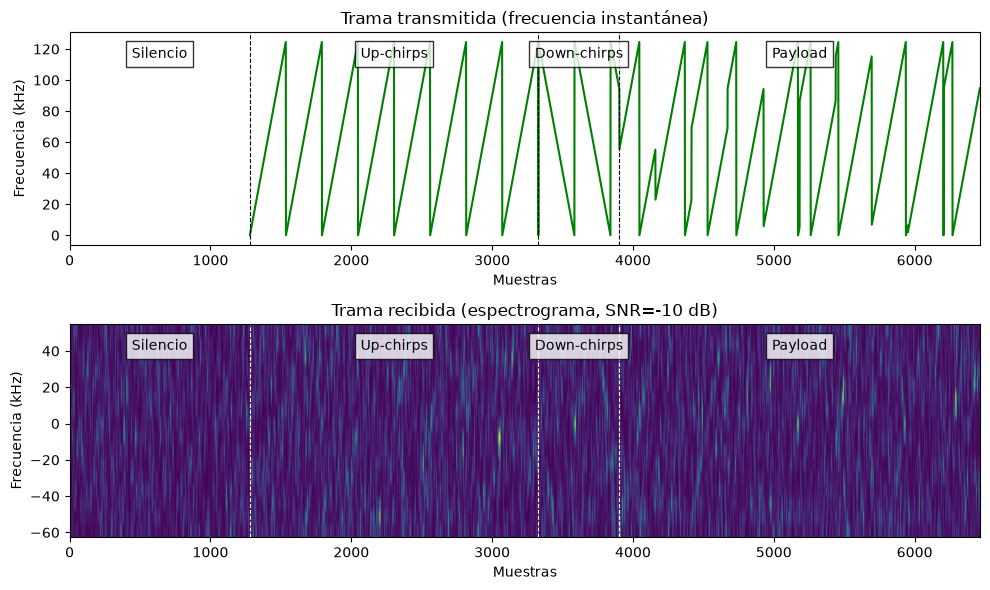

In [23]:
# Escenario para analizar las estrategias de detección
SF = 8
n_simbolos = 10  # Símbolos del payload
SNR_dB = -10
silencio = 5  # Símbolos de silencio antes de la trama: desconocido para el receptor
simbolos_tx = rng.integers(0, 2**SF, size=n_simbolos)
R_FA = 1 / 60  # Tasa de falsas alarmas tolerable: una por minuto
P_FA = R_FA * 2**SF / B  # Probabilidad de falsa alarma por símbolo: R_FA T_s

r = transmitir_trama(simbolos_tx, silencio, SF, B, SNR_dB, CANAL_PLANO)
r_limpia = transmitir_trama(simbolos_tx, silencio, SF, B, 100, CANAL_PLANO)  # Sin ruido apreciable
sigma2 = potencia_del_ruido(SF, B, SNR_dB)  # Conocida por el receptor

graficar_trama(r, simbolos_tx, silencio, SF, B, SNR_dB);

### Detección en el tiempo: correlación móvil con un up-chirp

En el tiempo el receptor no necesita sincronía de símbolo: desliza una plantilla conocida sobre la señal recibida, muestra a muestra, y busca dónde se parece más. La muestra $k$ donde se decide $H_1$ es a la vez la detección y la sincronización, porque es donde empieza la trama.

Para cada muestra $k$ se plantea un test de hipótesis binario:

- $H_0$: el preámbulo no empieza en la muestra $k$. Se recibe solo ruido, u otra parte de la trama.
- $H_1$: el preámbulo empieza en la muestra $k$, y $r_k = p + w$, donde $r_k$ son las muestras recibidas a partir de $k$, $p$ son los 8 *up-chirps* del preámbulo (conocidos) y $w$ es ruido gaussiano i.i.d.

Los dos métodos parten de la correlación móvil de la señal recibida con un solo *up-chirp* (símbolo 0):

$$
y[k] = \langle r_k, c|_{s=0} \rangle = \sum_{i=0}^{2^{SF}-1} r(kT + iT)\, c^*(iT)|_{s=0}
$$

Dentro del preámbulo, $|y[k]|^2$ es máxima cuando la plantilla queda alineada con un *up-chirp*, y nula con cualquier otro desplazamiento, porque un *up-chirp* desplazado en el tiempo es un *up-chirp* con un corrimiento de frecuencia, ortogonal al original.

Los picos aparecen cada $2^{SF}/2$ muestras y no cada $2^{SF}$. Como se vio en *Análisis de la señal modulada*, la frecuencia de la Ec. 2, cuya fase para el símbolo 0 es $2\pi k^2 / 2^{SF}$, barre de 0 a $2B$ y, muestreada a $B$, se repliega. Cada *up-chirp* son dos copias de un *chirp* de $2^{SF}/2$ muestras, y el preámbulo produce 16 picos.

In [ ]:
"""
Correlación móvil de r con una plantilla, calculada por FFT.

    Parámetros:
        r: Señal.
        plantilla: Señal conocida, no más larga que r.

    Devuelve:
        sum_i r[k + i] conj(plantilla[i]) para cada k donde entra la plantilla.
"""

def correlacion(r: np.ndarray, plantilla: np.ndarray) -> np.ndarray:

    # Correlación móvil de r con una plantilla conocida: sum_i r[k + i] conj(plantilla[i]) para
    # cada muestra k donde entra la plantilla completa. Se calcula por FFT, que da lo mismo que
    # np.correlate(r, plantilla, mode="valid") pero mucho más rápido con plantillas largas. Con n
    # >= r.size, la correlación circular de la FFT no se solapa en las posiciones válidas
    assert r.size >= plantilla.size, "La señal es más corta que la plantilla"
    n = 2 ** int(np.ceil(np.log2(r.size)))  # Potencia de 2 para que la FFT sea rápida
    y = np.fft.ifft(np.fft.fft(r, n) * np.conj(np.fft.fft(plantilla, n)))
    return y[: r.size - plantilla.size + 1]


"""
Correlación móvil y[k] de r con un up-chirp.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        y[k] para cada muestra k.
"""

def correlacion_upchirp(r: np.ndarray, SF: int, B: float) -> np.ndarray:

    # y[k] = <r_k, c|s=0>: correlación móvil con un up-chirp
    return correlacion(r, tabla_de_chirps(SF, B)[0])


"""
Grafica |y[k]|^2 sin ruido, con ruido, y el detalle del inicio del preámbulo.

    Parámetros:
        y_limpia: y[k] de la trama sin ruido.
        y: y[k] de la trama con ruido.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
"""

def graficar_correlacion_upchirp(
    y_limpia: np.ndarray, y: np.ndarray, silencio: int, SF: int, SNR_dB: float
):

    # |y[k]|^2 sin ruido y con ruido, y detalle del inicio del preámbulo
    N = 2**SF
    n_muestras = y.size + N - 1  # Largo de la señal recibida

    fig, axs = plt.subplots(3, 1, figsize=(10, 9))
    axs[0].plot(np.abs(y_limpia) ** 2, color="green", lw=0.8)
    axs[0].set(title="Correlación móvil con un up-chirp (sin ruido)")
    axs[1].plot(np.abs(y) ** 2, color="green", lw=0.8)
    axs[1].set(title=f"Correlación móvil con un up-chirp (SNR={SNR_dB} dB)")
    for ax in axs[:2]:
        marcar_partes_de_la_trama(ax, silencio, SF, n_muestras)

    # Detalle sin ruido del inicio del preámbulo, con los bordes de símbolo punteados
    axs[2].plot(np.abs(y_limpia) ** 2, marker=".", color="green", lw=0.8)
    for n in range(4):
        axs[2].axvline((silencio + n) * N, color="k", ls=":", lw=0.8)
    axs[2].set_xlim((silencio - 1) * N, (silencio + 3) * N)
    axs[2].set(title="Detalle del inicio del preámbulo (sin ruido): bordes de símbolo punteados")

    for ax in axs:
        ax.set(xlabel="k (muestra)", ylabel="$|y[k]|^2$")
    fig.tight_layout()
    return fig

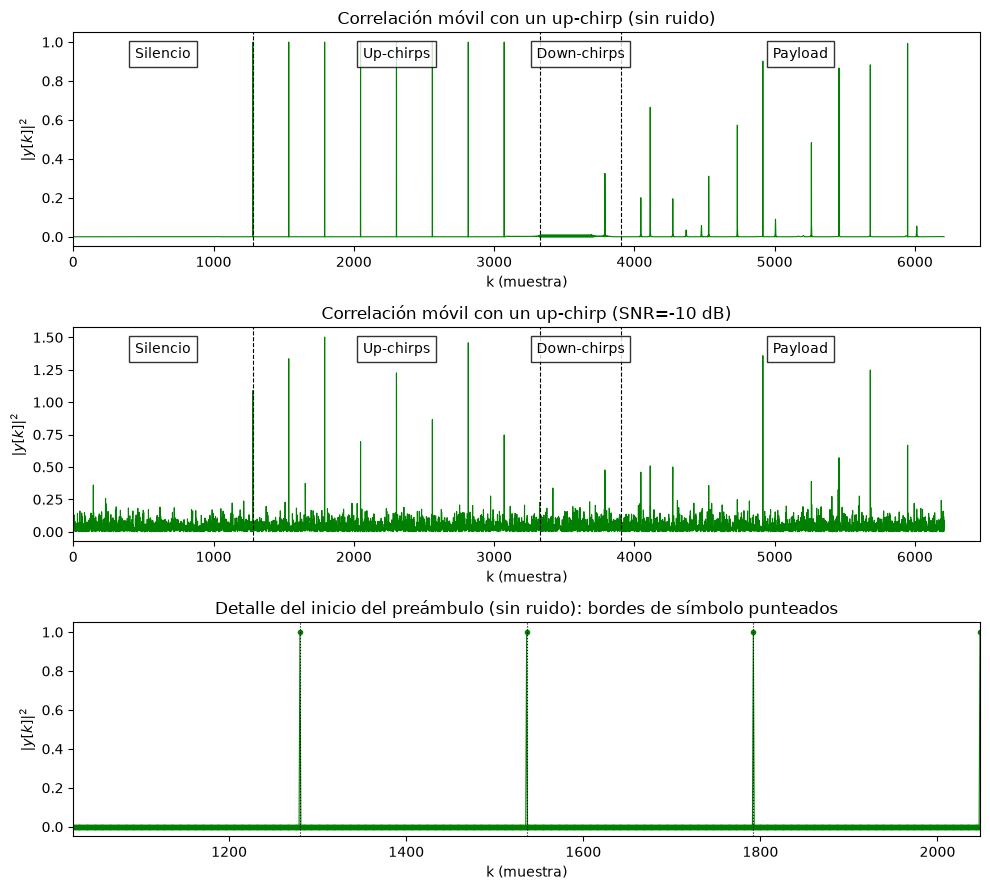

In [25]:
# Correlación móvil con un up-chirp sobre la trama del escenario, sin ruido y con ruido
y_limpia = correlacion_upchirp(r_limpia, SF, B)
y = correlacion_upchirp(r, SF, B)

graficar_correlacion_upchirp(y_limpia, y, silencio, SF, SNR_dB);

**Observaciones**:
- Sin ruido se ve la estructura de la trama: picos de altura 1 cada $2^{SF}/2$ muestras durante los *up-chirps*, nada en el silencio ni en los *down-chirps*, y picos aislados en el *payload* (donde un símbolo, o una mezcla de dos símbolos consecutivos, se parece a un *up-chirp*).
- Con ruido los picos del preámbulo siguen sobresaliendo, pero el ruido también produce picos: decidir con uno solo daría muchas falsas alarmas. Los dos métodos en el tiempo combinan los 8 picos que deja el preámbulo, separados un símbolo: uno en forma coherente y otro no coherente.

### Detección en el tiempo: correlación con el preámbulo completo

La plantilla es el preámbulo completo de 8 *up-chirps*, $p$. Es el problema de detectar una señal conocida en ruido gaussiano, donde el test de razón de verosimilitud se reduce a correlar la señal recibida con la señal conocida (filtro adaptado) y comparar con un umbral. Como la fase de la señal recibida es desconocida, se compara el módulo al cuadrado:

$$
T[k] = \left| \langle r_k, p \rangle \right|^2 = \left| \sum_{n=0}^{7} y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta
$$

Como $p$ son *up-chirps* repetidos, correlar con $p$ es sumar los 8 picos de $y[k]$ separados un símbolo. La suma es coherente, antes del módulo, así que las amplitudes de la señal se suman en fase (potencia $\times 64$) mientras que las potencias del ruido se suman ($\times 8$), una ganancia de $10\log_{10} 8 \approx 9$ dB respecto de un solo pico. A cambio, necesita que la fase de la señal se mantenga durante los 8 símbolos, lo que un corrimiento de frecuencia entre transmisor y receptor impediría.

**Umbral (Neyman-Pearson)**: no se conocen las probabilidades *a priori* de $H_0$ y $H_1$, así que se fija la $P_{FA}$ tolerable. Cada *chirp* tiene energía 1, así que bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, la suma de 8 tiene varianza $8\sigma^2$ y $T[k]$ tiene distribución exponencial de media $8\sigma^2$:

$$
P_{FA} = P(T[k] > \eta \mid H_0) = e^{-\eta / 8\sigma^2} \quad\Rightarrow\quad \eta = -8\sigma^2 \ln P_{FA}
$$

El test se repite en las $2^{SF}$ muestras de cada símbolo, así que para tener la misma tasa de falsas alarmas que un test por símbolo se usa $P_{FA} / 2^{SF}$ en cada muestra.

**Inicio de la trama**: cada $2^{SF}/2$ muestras la plantilla vuelve a alinearse con parte del preámbulo, así que alrededor del inicio $T[k]$ es un peine, con $T \approx 64\,(1 - j/16)^2$ cuando quedan $j$ medios *chirps* afuera. El primer cruce del umbral suele ser uno de estos picos laterales, antes del inicio, así que el inicio se estima como el máximo de $T[k]$ en los 8 símbolos siguientes al primer cruce. La búsqueda se repite desde ese máximo hasta que ningún valor de los 8 símbolos siguientes lo supere, por si el primer cruce llega más de 8 símbolos antes del inicio, como ocurre en el SDR (ver *SNR y FER según la atenuación del TX*).

In [ ]:
"""
Estadístico T[k] = |<r_k, p>|^2 de la correlación con el preámbulo completo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        T[k] para cada muestra k donde entra el preámbulo.
"""

def correlacion_preambulo(r: np.ndarray, SF: int, B: float) -> np.ndarray:

    # T[k] = |<r_k, p>|^2, con p los N_UPCHIRPS up-chirps del preámbulo (filtro adaptado). Equivale
    # a sumar los picos y[k + n 2^SF] antes del módulo (integración coherente)
    plantilla = np.tile(tabla_de_chirps(SF, B)[0], N_UPCHIRPS)
    return np.abs(correlacion(r, plantilla)) ** 2


"""
Umbral de Neyman-Pearson de T[k].

    Parámetros:
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por muestra.

    Devuelve:
        El umbral eta.
"""

def umbral_correlacion(sigma2: float, P_FA: float) -> float:

    # Neyman-Pearson para T[k], con la P_FA por muestra. Bajo H0, T[k] es exponencial de media
    # N_UPCHIRPS sigma^2, porque cada chirp tiene energía 1: P_FA = e^{-eta / (N_UPCHIRPS sigma^2)}
    return -N_UPCHIRPS * sigma2 * np.log(P_FA)


"""
Busca el inicio de la trama: el máximo del estadístico después del primer cruce.

    Parámetros:
        estadistico: Estadístico de cada posición (muestra o ventana).
        eta: Umbral.
        ventana: Posiciones donde se busca el máximo después del cruce.

    Devuelve:
        La posición del inicio, o None si no se detecta la trama.
"""

def detectar_inicio(estadistico: np.ndarray, eta: float, ventana: int) -> int | None:

    # Declara la trama presente (H1) en la primera posición donde el estadístico alcanza el umbral
    # eta. Como las posiciones anteriores al inicio ya se superponen con parte del preámbulo, el
    # primer cruce suele llegar antes de tiempo: el inicio es el máximo del estadístico en las
    # `ventana` posiciones siguientes. La búsqueda se repite desde ese máximo hasta que ninguna de
    # las `ventana` posiciones siguientes lo supere, por si el cruce llegó más de `ventana`
    # posiciones antes del inicio (en el SDR, la cola de la trama anterior puede superar el umbral)
    cruces = np.flatnonzero(estadistico >= eta)
    if cruces.size == 0:
        return None  # No se detecta la trama: H0 en todas las posiciones

    inicio = int(cruces[0])
    while True:
        maximo = inicio + int(np.argmax(estadistico[inicio : inicio + ventana]))
        if maximo == inicio:
            return inicio
        inicio = maximo


"""
Detecta el inicio de la trama con la correlación con el preámbulo completo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
"""

def detectar_preambulo_completo(
    r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float
) -> int | None:

    # Muestra de inicio de la trama, o None. P_FA es por símbolo: en el tiempo se prueban 2^SF
    # muestras por símbolo, así que cada una usa P_FA / 2^SF
    N = 2**SF
    eta = umbral_correlacion(sigma2, P_FA / N)
    return detectar_inicio(correlacion_preambulo(r, SF, B), eta, N_UPCHIRPS * N)


"""
Marca el inicio real y el detectado.

    Parámetros:
        ax: Ejes donde se dibuja.
        real: Inicio real.
        inicio: Inicio detectado, o None.
"""

def marcar_inicios(ax: plt.Axes, real: int, inicio: int | None) -> None:

    # Inicio real (negro) e inicio detectado (rojo punteado)
    ax.axvline(real, color="k", ls="--", lw=0.8, label="Inicio real")
    if inicio is not None:
        ax.axvline(inicio, color="r", ls=":", label="Inicio detectado")


"""
Grafica T[k] con el umbral, el inicio real y el detectado.

    Parámetros:
        T: Estadístico T[k].
        eta: Umbral.
        inicio: Muestra de inicio detectada, o None.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
"""

def graficar_deteccion_preambulo(
    T: np.ndarray,
    eta: float,
    inicio: int | None,
    silencio: int,
    SF: int,
    P_FA: float,
    SNR_dB: float,
):

    # Estadístico T[k] con el umbral, el inicio real y el detectado
    N = 2**SF
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(T, color="green", lw=0.8)
    ax.axhline(
        eta, color="r", ls="--", lw=0.8, label=f"Umbral η ($P_{{FA}}$={P_FA:.1e} por símbolo)"
    )
    marcar_inicios(ax, silencio * N, inicio)
    ax.set(
        title=f"Correlación con el preámbulo completo: inicio real k={silencio * N}, "
        f"detectado k={inicio} (SNR={SNR_dB} dB)",
        xlabel="k (muestra)",
        ylabel="$T[k]$",
        xlim=(0, T.size + N_UPCHIRPS * N - 1),  # Largo de la señal recibida
    )
    ax.legend(loc="upper right")
    fig.tight_layout()
    return fig

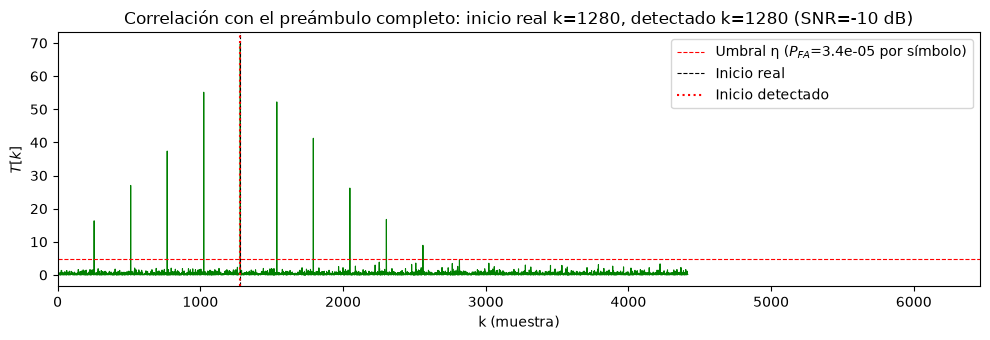

In [27]:
# Correlación con el preámbulo completo sobre el escenario
eta = umbral_correlacion(sigma2, P_FA / 2**SF)  # P_FA por muestra: 2^SF muestras por símbolo
T = correlacion_preambulo(r, SF, B)
inicio = detectar_inicio(T, eta, N_UPCHIRPS * 2**SF)

graficar_deteccion_preambulo(T, eta, inicio, silencio, SF, P_FA, SNR_dB);

### Detección en el tiempo: búsqueda de 8 picos

En lugar de un pico de la correlación con el preámbulo completo, se buscan los 8 picos seguidos, separados un tiempo de símbolo ($2^{SF}$ muestras), que deja el preámbulo en la correlación móvil con un solo *up-chirp*. El estadístico suma la energía de los 8 picos candidatos a partir de la muestra $k$:

$$
S[k] = \sum_{n=0}^{7} \left| y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_S
$$

La diferencia con $T[k]$ es dónde se toma el módulo. $T[k]$ suma los picos y después toma el módulo (integración coherente); $S[k]$ toma el módulo de cada pico y después suma (integración no coherente). Al sumar energías se descarta la fase de cada pico, así que el método tolera que la fase cambie entre símbolos. A cambio, el ruido de cada pico suma su energía en lugar de promediarse con el de los demás, y se espera que necesite más SNR que $T[k]$.

Los picos intermedios, a $2^{SF}/2$ muestras, no se usan. Con picos separados un símbolo las 8 correlaciones usan muestras disjuntas, y bajo $H_0$ son independientes.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, así que $|y|^2$ es exponencial de media $\sigma^2$. Los 8 son independientes, por lo que $S[k]$ tiene distribución Gamma de orden 8 (Erlang) y escala $\sigma^2$, con cola en forma cerrada:

$$
P_{FA} = P(S[k] > \eta_S \mid H_0) = e^{-\eta_S/\sigma^2} \sum_{i=0}^{7} \frac{(\eta_S/\sigma^2)^i}{i!}
$$

$\eta_S$ no se puede despejar, pero como la cola es decreciente en $\eta_S$, se busca por bisección. Igual que en $T[k]$, se usa $P_{FA} / 2^{SF}$ por muestra.

**Inicio de la trama**: $S[k]$ también es un peine alrededor del inicio, y el inicio se estima de la misma forma. Sus picos laterales son más altos, relativos al principal, que los de $T[k]$. Con medio símbolo de error $S \approx 7.25$, contra 8 en el inicio, mientras que $T$ baja de 64 a $\approx 56$.

In [ ]:
"""
Estadístico S[k]: energía de N_UPCHIRPS picos de y[k] separados un símbolo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        S[k] para cada muestra k donde entran todos los picos.
"""

def estadistico_picos(r: np.ndarray, SF: int, B: float) -> np.ndarray:

    # S[k] = suma de |y[k + n 2^SF]|^2 para n = 0..N_UPCHIRPS-1: energía de N_UPCHIRPS picos
    # separados un símbolo. El módulo se toma antes de sumar (integración no coherente)
    N = 2**SF
    assert r.size >= N_UPCHIRPS * N, "La señal es más corta que los up-chirps del preámbulo"
    y2 = np.abs(correlacion_upchirp(r, SF, B)) ** 2

    # Posiciones k donde entran todos los picos: mismo largo que correlacion_preambulo
    n_validas = y2.size - (N_UPCHIRPS - 1) * N

    S = np.zeros(n_validas)
    for n in range(N_UPCHIRPS):
        S += y2[n * N : n * N + n_validas]  # Pico n: n símbolos después de k
    return S


"""
Umbral de Neyman-Pearson de S[k], buscado por bisección.

    Parámetros:
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por muestra.

    Devuelve:
        El umbral eta_S.
"""

def umbral_picos(sigma2: float, P_FA: float) -> float:

    # Neyman-Pearson para S[k], con la P_FA por muestra. Bajo H0, S[k] es Gamma de orden
    # N_UPCHIRPS y escala sigma^2 (Erlang). Su cola no se puede invertir en forma cerrada, así que
    # el umbral se busca por bisección

    """
    Probabilidad de que S[k] supere x sigma^2 bajo H0.

        Parámetros:
            x: Umbral dividido por sigma^2.

        Devuelve:
            La probabilidad.
    """

    def cola(x):

        # P(S[k] > x sigma^2 | H0)
        return np.exp(-x) * sum(x**i / factorial(i) for i in range(N_UPCHIRPS))

    # Intervalo [abajo, arriba] que contiene la solución: se duplica `arriba` hasta que la cola
    # baje de P_FA
    abajo, arriba = 0.0, 1.0
    while cola(arriba) > P_FA:
        abajo, arriba = arriba, 2 * arriba

    # Bisección: la cola es decreciente en x
    for _ in range(60):
        medio = (abajo + arriba) / 2
        if cola(medio) > P_FA:
            abajo = medio
        else:
            arriba = medio
    return arriba * sigma2


"""
Detecta el inicio de la trama con la búsqueda de 8 picos.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
"""

def detectar_picos(r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float) -> int | None:

    # Muestra de inicio de la trama, o None. P_FA es por símbolo: cada muestra usa P_FA / 2^SF
    N = 2**SF
    eta_S = umbral_picos(sigma2, P_FA / N)
    return detectar_inicio(estadistico_picos(r, SF, B), eta_S, N_UPCHIRPS * N)


"""
Grafica |y[k]|^2 con los picos del inicio detectado, y S[k] con su umbral.

    Parámetros:
        y: Correlación móvil con un up-chirp.
        S: Estadístico S[k].
        eta_S: Umbral.
        inicio: Muestra de inicio detectada, o None.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
"""

def graficar_deteccion_picos(
    y: np.ndarray,
    S: np.ndarray,
    eta_S: float,
    inicio: int | None,
    silencio: int,
    SF: int,
    P_FA: float,
    SNR_dB: float,
):

    # |y[k]|^2 con los picos del inicio detectado, y S[k] con su umbral
    N = 2**SF
    n_muestras = y.size + N - 1  # Largo de la señal recibida

    fig, axs = plt.subplots(2, 1, figsize=(10, 6))
    axs[0].plot(np.abs(y) ** 2, color="green", lw=0.8)
    if inicio is not None:
        # Los picos que suma S[k] en el inicio detectado
        picos = inicio + np.arange(N_UPCHIRPS) * N
        axs[0].plot(
            picos,
            np.abs(y[picos]) ** 2,
            "o",
            mfc="none",
            color="r",
            label=f"{N_UPCHIRPS} picos del inicio detectado",
        )
        axs[0].legend(loc="upper right")
    axs[0].set(title=f"Correlación móvil con un up-chirp (SNR={SNR_dB} dB)", ylabel="$|y[k]|^2$")

    axs[1].plot(S, color="green", lw=0.8)
    axs[1].axhline(
        eta_S, color="r", ls="--", lw=0.8, label=f"Umbral $η_S$ ($P_{{FA}}$={P_FA:.1e} por símbolo)"
    )
    marcar_inicios(axs[1], silencio * N, inicio)
    axs[1].set(
        title=f"Búsqueda de {N_UPCHIRPS} picos: inicio real k={silencio * N}, detectado "
        f"k={inicio} (SNR={SNR_dB} dB)",
        ylabel="$S[k]$",
    )
    axs[1].legend(loc="upper right")

    for ax in axs:
        ax.set(xlabel="k (muestra)", xlim=(0, n_muestras))
    fig.tight_layout()
    return fig

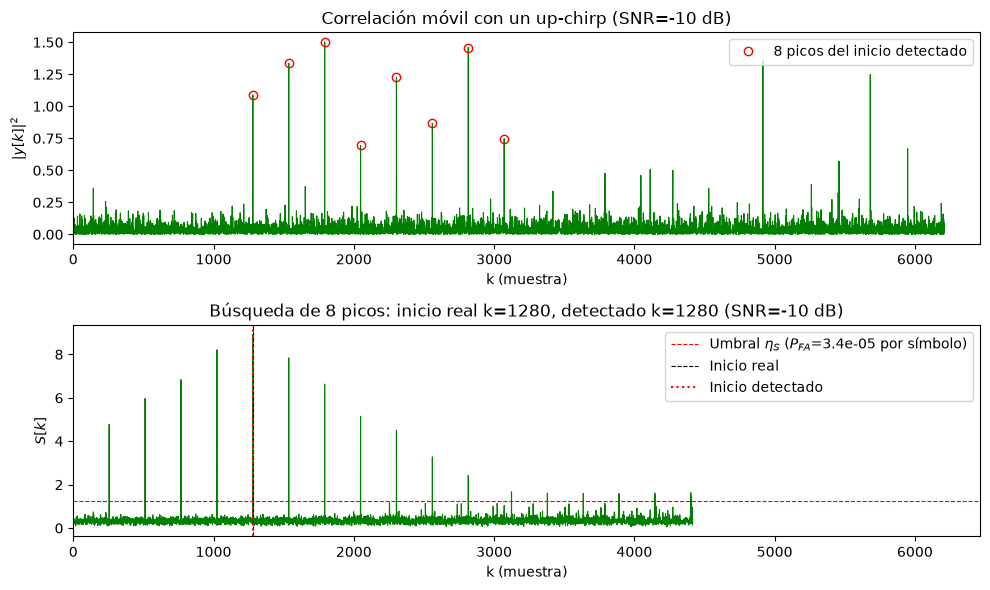

In [29]:
# Búsqueda de 8 picos sobre el escenario
eta_S = umbral_picos(sigma2, P_FA / 2**SF)  # P_FA por muestra: 2^SF muestras por símbolo
S = estadistico_picos(r, SF, B)
inicio = detectar_inicio(S, eta_S, N_UPCHIRPS * 2**SF)

graficar_deteccion_picos(y, S, eta_S, inicio, silencio, SF, P_FA, SNR_dB);

### Detección en frecuencia: demodulación del preámbulo

A diferencia de la detección en el tiempo, se asume sincronía de símbolo. El receptor divide la señal recibida en ventanas de $2^{SF}$ muestras alineadas con los bordes de los símbolos, y lo que no conoce es en qué ventana $m$ empieza la trama. Las hipótesis son las mismas que en el tiempo, por ventana en lugar de por muestra.

La estrategia en frecuencia reutiliza el demodulador (Ec. 16): cada ventana se multiplica por el *down-chirp* y se calcula su FFT. Durante el preámbulo cada ventana es un *up-chirp* de símbolo 0, por lo que el pico de la FFT aparece en el bin $q = 0$.

Mirar solo el bin 0 no aporta nada nuevo, porque $D_n[0]$ es la correlación móvil $y[k]$ de la detección en el tiempo evaluada en el borde de la ventana, $k = n\,2^{SF}$. La diferencia está en comparar el bin 0 con los demás bins en vez de con un umbral absoluto. El estadístico es la cantidad de ventanas, entre 8 consecutivas, en las que el demodulador decide el símbolo $\hat{s}[n] = 0$:

$$
V[m] = \sum_{n=m}^{m+7} \mathbb{1}\{\hat{s}[n] = 0\} \;\underset{H_0}{\overset{H_1}{\gtrless}}\; K
$$

Un umbral $K < 8$ tolera ventanas del preámbulo mal decididas por el ruido. El inicio se estima igual que en el tiempo: el máximo de $V[m]$ después del primer cruce.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada ventana es ruido blanco gaussiano, y su FFT (unitaria) también lo es, así que el máximo cae en cualquiera de los $2^{SF}$ bins con igual probabilidad y cada ventana se decide como símbolo 0 con probabilidad $p_0 = 2^{-SF}$. El ruido de ventanas distintas es independiente, por lo que $V[m]$ tiene distribución binomial $\mathcal{B}(8, p_0)$:

$$
P_{FA}(K) = P(V[m] \geq K \mid H_0) = \sum_{k=K}^{8} \binom{8}{k} p_0^k (1 - p_0)^{8-k}
$$

$V[m]$ es discreto, así que en general ningún $K$ da exactamente la $P_{FA}$ pedida. Bajar el umbral sube la $P_D$, por lo que Neyman-Pearson elige el menor $K$ con $P_{FA}(K) \leq P_{FA}$. Hay un test por ventana, así que $P_{FA}$ se usa sin dividir. Para $SF = 8$ y $P_{FA} \approx 3.4 \cdot 10^{-5}$, $P_{FA}(2) \approx 4.2 \cdot 10^{-4}$ no la respeta y $P_{FA}(3) \approx 3.3 \cdot 10^{-6}$ sí, así que $K = 3$, con una $P_{FA}$ unas 10 veces menor que la tolerada.

- **Ventaja**: el umbral no depende de $\sigma^2$, ya que la decisión de cada ventana es relativa entre bins y la distribución de $V[m]$ bajo $H_0$ solo depende de $SF$. No hace falta conocer ni estimar la potencia del ruido.
- **Desventaja**: cada ventana toma una decisión dura con la energía de un solo símbolo, y se pierde la ganancia de 9 dB de la suma coherente. Se espera que necesite más SNR que la detección en el tiempo.
- **Empates**: con probabilidad $2^{-SF}$ la ventana de ruido justo antes del preámbulo también se decide como símbolo 0, y $V[m]$ empata en 8 con el inicio real. Se elige la primera ventana del empate, un error de $\approx 0.4\%$ que no baja con el SNR. En el tiempo no hay empates, porque $T[k]$ es continuo.

In [ ]:
"""
Estadístico V[m]: ventanas decididas como 0 entre las N_UPCHIRPS a partir de m.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        V[m] para cada ventana m donde entra el preámbulo.
"""

def conteo_de_ceros(r: np.ndarray, SF: int) -> np.ndarray:

    # V[m]: cantidad de ventanas decididas como símbolo 0 entre las N_UPCHIRPS a partir de m
    N = 2**SF
    assert r.size >= N_UPCHIRPS * N, "La señal es más corta que los up-chirps del preámbulo"

    # Demodular cada ventana de 2^SF muestras (sincronía de símbolo). Se descarta el resto
    simbolos_rx = demodulador(r[: r.size // N * N], SF)

    # 1 si el pico de la FFT de la ventana está en el bin 0, como en un up-chirp del preámbulo
    es_cero = (simbolos_rx == 0).astype(int)

    # Suma de N_UPCHIRPS ventanas consecutivas a partir de cada m
    return np.convolve(es_cero, np.ones(N_UPCHIRPS, dtype=int), mode="valid")


"""
Probabilidad de falsa alarma de V[m] con umbral K.

    Parámetros:
        K: Umbral.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        P(V[m] >= K | H0).
"""

def falsa_alarma_conteo(K: int, SF: int) -> float:

    # P(V[m] >= K | H0). Bajo H0, cada ventana se decide como símbolo 0 con probabilidad 2^-SF,
    # así que V[m] tiene distribución binomial B(N_UPCHIRPS, 2^-SF)
    p0 = 2.0**-SF
    n = N_UPCHIRPS
    return sum(comb(n, k) * p0**k * (1 - p0) ** (n - k) for k in range(K, n + 1))


"""
Umbral de Neyman-Pearson de V[m]: el menor K que cumple la P_FA.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        P_FA: Probabilidad de falsa alarma por ventana.

    Devuelve:
        El umbral K.
"""

def umbral_conteo(SF: int, P_FA: float) -> int:

    # Neyman-Pearson para V[m], con la P_FA por ventana. Como V[m] es discreto, se elige el menor
    # K (mayor P_D) cuya P_FA no supera la pedida. Con K = N_UPCHIRPS + 1 nunca se decide H1, así
    # que siempre hay solución
    for K in range(N_UPCHIRPS + 2):
        if falsa_alarma_conteo(K, SF) <= P_FA:
            return K


"""
Detecta el inicio de la trama con la demodulación del preámbulo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: No se usa: está para tener la misma firma que los otros detectores.
        sigma2: No se usa, igual que B.
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
"""

def detectar_frecuencia(r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float) -> int | None:

    # Muestra de inicio de la trama, o None. Hay un test por ventana, así que usa la P_FA por
    # símbolo. B y sigma2 no se usan: están para tener la misma firma que los detectores en el
    # tiempo
    K = umbral_conteo(SF, P_FA)
    inicio = detectar_inicio(conteo_de_ceros(r, SF), K, N_UPCHIRPS)
    return None if inicio is None else inicio * 2**SF  # La ventana m empieza en m 2^SF


"""
Grafica el símbolo decidido en cada ventana, y V[m] con su umbral.

    Parámetros:
        simbolos_rx: Símbolo decidido en cada ventana.
        V: Estadístico V[m].
        K: Umbral.
        inicio: Ventana de inicio detectada, o None.
        silencio: Símbolos de silencio antes de la trama.
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
"""

def graficar_deteccion_frecuencia(
    simbolos_rx: np.ndarray,
    V: np.ndarray,
    K: int,
    inicio: int | None,
    silencio: int,
    P_FA: float,
    SNR_dB: float,
):

    # Símbolo decidido en cada ventana, y V[m] con su umbral. `inicio` es una ventana
    fig, axs = plt.subplots(2, 1, figsize=(10, 6))
    axs[0].plot(simbolos_rx, "o", color="green")
    axs[0].axvspan(
        silencio - 0.5,
        silencio + N_UPCHIRPS - 0.5,
        color="k",
        alpha=0.1,
        label="Up-chirps del preámbulo",
    )
    axs[0].set(
        title="Símbolo decidido en cada ventana", xlabel="n (ventana)", ylabel=r"$\hat{s}[n]$"
    )

    axs[1].plot(V, marker="o", color="green")
    axs[1].axhline(K, color="r", ls="--", lw=0.8, label=f"Umbral K={K} ($P_{{FA}}$={P_FA:.1e})")
    axs[1].axvline(silencio, color="k", ls="--", lw=0.8, label="Inicio real")
    axs[1].set(
        title=f"Detección en frecuencia: inicio real m={silencio}, detectado m={inicio} "
        f"(SNR={SNR_dB} dB)",
        xlabel="m (ventana)",
        ylabel="$V[m]$",
    )

    for ax in axs:
        ax.legend()
    fig.tight_layout()
    return fig

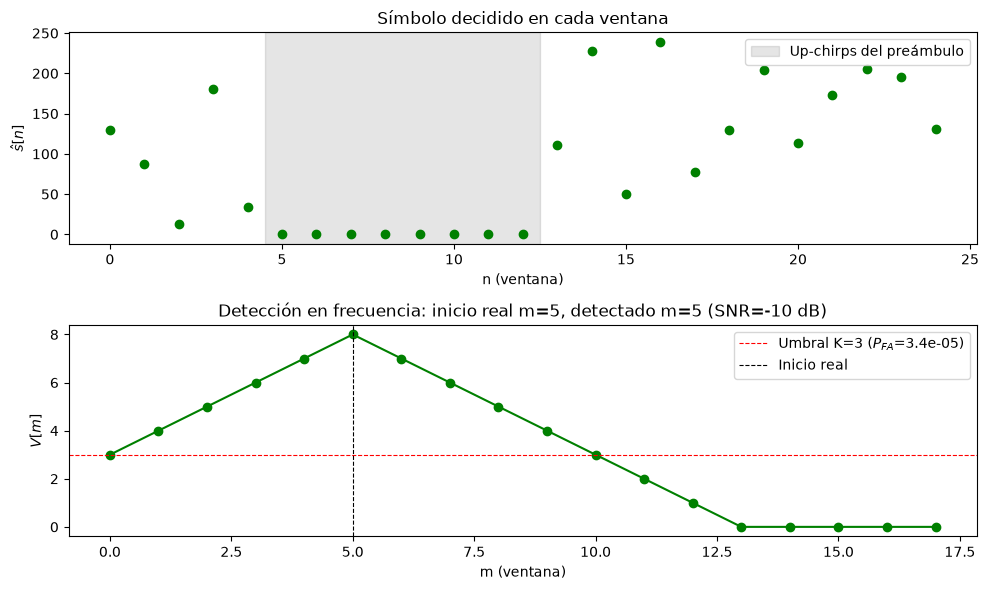

In [31]:
# Detección en frecuencia sobre el escenario
K = umbral_conteo(SF, P_FA)  # Un test por ventana: la P_FA por símbolo
V = conteo_de_ceros(r, SF)
inicio = detectar_inicio(V, K, N_UPCHIRPS)

# Símbolo decidido en cada ventana, para ver qué ventanas cuentan en V[m]
simbolos_rx = demodulador(r[: r.size // 2**SF * 2**SF], SF)

graficar_deteccion_frecuencia(simbolos_rx, V, K, inicio, silencio, P_FA, SNR_dB);

### Comparación de los métodos

#### Frame Error Rate (FER)

El *Frame Error Rate* (FER) es la fracción de tramas cuyo inicio el receptor no estima en la muestra exacta, ya sea porque no detecta la trama (*miss*), porque se adelanta (falsa alarma) o porque se atrasa. Un inicio corrido una sola muestra cuenta como error, porque el demodulador corta los símbolos del *payload* a partir de él. Los errores del *payload* con el inicio correcto no cuentan, porque los mide el BER (ver *BER en función del SNR*).

Se simula el FER de los tres métodos en ambos canales. Junto con la ROC, es la métrica para comparar los detectores. El FER cae varios órdenes de magnitud en pocos dB, así que el eje es logarítmico. Cada SNR se simula hasta juntar 30 tramas perdidas o llegar a 2000 tramas, así que el menor FER que se puede medir es $1/2000 = 5 \cdot 10^{-4}$, y los puntos sin errores no se dibujan.

In [ ]:
"""
Estima el FER de un detector para un SNR, simulando tramas.

    Parámetros:
        detector: Función detector(r, SF, B, sigma2, P_FA).
        SNR_dB: SNR, en dB.
        h: Respuesta al impulso del canal.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        P_FA: Probabilidad de falsa alarma por símbolo.
        max_tramas: Máximo de tramas simuladas.
        n_simbolos: Símbolos del payload.
        silencio: Símbolos de silencio antes de la trama.
        min_errores: Tramas perdidas con las que se deja de simular.

    Devuelve:
        El FER.
"""

def fer_en_snr(
    detector,
    SNR_dB: float,
    h: np.ndarray,
    SF: int,
    B: float,
    P_FA: float,
    max_tramas: int,
    n_simbolos: int,
    silencio: int,
    min_errores: int,
) -> float:

    # Simula tramas y estima el FER para un SNR. Una trama se pierde si el detector no estima su
    # inicio en la muestra exacta: no la detecta, o la detecta antes (falsa alarma) o después.
    # Termina al juntar min_errores tramas perdidas o al llegar a max_tramas: donde el FER es alto
    # alcanzan pocas tramas, y las demás se usan donde es bajo
    sigma2 = potencia_del_ruido(SF, B, SNR_dB)  # El receptor la conoce
    tramas = errores = 0
    while tramas < max_tramas and errores < min_errores:
        simbolos = rng.integers(0, 2**SF, size=n_simbolos)
        r = transmitir_trama(simbolos, silencio, SF, B, SNR_dB, h)
        errores += detector(r, SF, B, sigma2, P_FA) != silencio * 2**SF
        tramas += 1
    return errores / tramas


"""
Estima el FER de un detector para cada SNR, con fer_en_snr.

    Parámetros:
        detector: Función detector(r, SF, B, sigma2, P_FA).
        SNRs_dB: SNR a simular, en dB.
        h: Respuesta al impulso del canal.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        P_FA: Probabilidad de falsa alarma por símbolo.
        max_tramas: Máximo de tramas simuladas por SNR.
        n_simbolos: Símbolos del payload.
        silencio: Símbolos de silencio antes de la trama.
        min_errores: Tramas perdidas con las que se deja de simular cada SNR.

    Devuelve:
        El FER de cada SNR.
"""

def fer_vs_snr(
    detector,
    SNRs_dB: np.ndarray,
    h: np.ndarray,
    SF: int,
    B: float,
    P_FA: float,
    max_tramas: int,
    n_simbolos: int,
    silencio: int,
    min_errores: int,
) -> np.ndarray:

    # FER para cada SNR, con fer_en_snr
    fers = []
    for SNR_dB in SNRs_dB:
        fer = fer_en_snr(
            detector, SNR_dB, h, SF, B, P_FA, max_tramas, n_simbolos, silencio, min_errores
        )
        fers.append(fer)
    return np.array(fers)


# Nombre y color de cada método en los gráficos
METODOS = {
    "completo": ("Tiempo (preámbulo completo)", "C0"),
    "picos": ("Tiempo (8 picos)", "C2"),
    "frecuencia": ("Frecuencia (demodulación)", "C1"),
}


"""
Grafica una métrica de cada método vs SNR, un gráfico por canal.

    Parámetros:
        SNRs_dB: SNR simulados, en dB.
        plano: Métrica de cada método en el canal plano, por clave de METODOS.
        selectivo: Métrica de cada método en el canal selectivo.
        nombre_metrica: Etiqueta del eje vertical.
        titulo: Título de la figura.
        logy: Eje vertical logarítmico.

    Devuelve:
        La figura.
"""

def graficar_comparacion(
    SNRs_dB: np.ndarray,
    plano: dict[str, np.ndarray],
    selectivo: dict[str, np.ndarray],
    nombre_metrica: str,
    titulo: str,
    logy: bool = False,
):

    # Una métrica de cada método vs SNR, un gráfico por canal. Con logy, los puntos en 0 no se
    # dibujan
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, metrica, nombre_canal in zip(
        axs, (plano, selectivo), ("Canal plano", "Canal selectivo")
    ):
        for metodo, valores in metrica.items():
            nombre, color = METODOS[metodo]
            ax.plot(SNRs_dB, valores, color=color, marker="o", label=nombre)
        if logy:
            ax.set_yscale("log", nonpositive="mask")
        ax.set(title=nombre_canal, xlabel="SNR (dB)")
        ax.grid(True, which="both" if logy else "major", alpha=0.5)
    axs[0].set_ylabel(nombre_metrica)
    axs[0].legend()
    fig.suptitle(titulo)
    fig.tight_layout()
    return fig

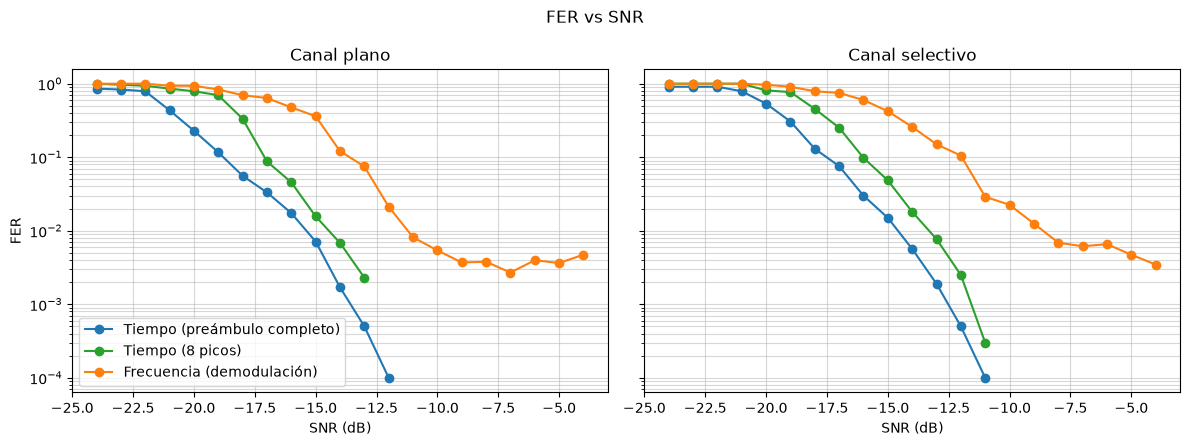

In [33]:
SNRs_fer_dB = np.arange(-24.0, -3.0, 1.0)  # -24 a -4 dB
detectores = {
    "completo": detectar_preambulo_completo,
    "picos": detectar_picos,
    "frecuencia": detectar_frecuencia,
}

fer_plano, fer_selectivo = {}, {}
for metodo, detector in detectores.items():
    for fer, h in ((fer_plano, CANAL_PLANO), (fer_selectivo, CANAL_SELECTIVO)):
        fer[metodo] = fer_vs_snr(
            detector, SNRs_fer_dB, h, SF, B, P_FA, 10000, n_simbolos, silencio, min_errores=30
        )

graficar_comparacion(SNRs_fer_dB, fer_plano, fer_selectivo, "FER", "FER vs SNR", logy=True);

**Observaciones**:
- Orden de los métodos, en ambos canales: correlación con el preámbulo completo, búsqueda de 8 picos y demodulación del preámbulo, con unos 2 dB entre cada uno (FER de 0.5 cerca de $-20$, $-18$ y $-16$ dB en el canal plano).
- **Integración coherente contra no coherente**: los dos métodos en el tiempo usan los mismos 8 picos de $y[k]$. Sumarlos antes del módulo (preámbulo completo) gana unos 2 dB frente a sumar sus energías (8 picos), a cambio de necesitar que la fase se mantenga durante el preámbulo.
- **Decisión blanda contra decisión dura**: los métodos en el tiempo conservan cuánto se parece cada posición a un *up-chirp*. La demodulación reduce cada ventana a "símbolo 0 o no", perdiendo información, y además necesita sincronía de símbolo.
- En el tiempo, por debajo de un FER de $\approx 0.4$ la caída se hace más lenta (con el preámbulo completo, de 0.38 a $-20$ dB a 0.30 a $-18$ dB). Las tramas ya se detectan, pero algunas con el inicio en un pico lateral del peine, medio símbolo o un símbolo corrido (ver *Detección en el tiempo: correlación con el preámbulo completo* y *FER por el aire*). Los picos laterales a medio símbolo aparecen porque la frecuencia de la Ec. 2 recorre la banda dos veces por símbolo (ver *Análisis de la señal modulada*). Con un *chirp* de una sola pasada, como $\tilde{c}$, la plantilla corrida medio símbolo no vuelve a alinearse, así que este tramo podría ser distinto.
- La demodulación del preámbulo tiene un piso de entre $2 \cdot 10^{-3}$ y $7 \cdot 10^{-3}$ desde $-10$ dB, por los empates descriptos en la detección en frecuencia ($\approx 0.4\%$). Los métodos en el tiempo no tienen piso, y en el canal plano desde $-7$ dB no pierden ninguna trama en 2000.
- El canal selectivo desplaza todas las curvas $\approx 1$ dB sin cambiar el orden. La plantilla solo captura el camino principal, que lleva el 80 % de la energía ($10\log_{10} 0.8 \approx -1$ dB).
- La correlación con el preámbulo completo es también la más costosa, porque aplica en cada muestra un filtro de $8 \cdot 2^{SF}$ coeficientes. La demodulación del preámbulo, en cambio, reutiliza el demodulador, con una FFT por símbolo.

#### Curva ROC

El FER mezcla detección y localización, porque una trama detectada con el inicio corrido también se pierde. Para comparar los métodos solo como detectores se usa el test binario en una posición (una muestra en el tiempo, una ventana en frecuencia):

- $H_0$: los 8 símbolos a partir de la posición contienen solo ruido.
- $H_1$: la posición está alineada con el inicio del preámbulo.

Cada umbral define un punto de operación ($P_{FA}$, $P_D$), con $P_D = P(\text{'}H_1\text{'} \mid H_1)$. La curva ROC (*Receiver Operating Characteristic*) recorre todos los umbrales y muestra el compromiso entre ambas probabilidades, ya que subir el umbral reduce las falsas alarmas a costa de perder detecciones. Neyman-Pearson elige el punto de la curva con la mayor $P_D$ que respeta la $P_{FA}$ tolerable (estrellas), y un detector es mejor que otro si su curva queda por encima.

El eje es la $P_{FA}$ por símbolo. En el tiempo se prueban $2^{SF}$ posiciones por símbolo, así que su tasa de falsas alarmas por símbolo es $2^{SF}$ veces la $P_{FA}$ por muestra, y con este eje los tres métodos se comparan a la misma tasa. Como la distribución de cada estadístico bajo $H_0$ es conocida, la $P_{FA}$ se calcula con el umbral (ver *Anexo A: falsas alarmas*) y solo se estima $P_D$. Las curvas empíricas (punteadas), que estiman también la $P_{FA}$, validan las teóricas donde se pueden medir. La curva de la detección en frecuencia es una escalera, porque $V[m]$ solo toma 9 valores.

In [ ]:
"""
Curva ROC empírica a partir de realizaciones de un estadístico.

    Parámetros:
        h0: Realizaciones bajo H0.
        h1: Realizaciones bajo H1.

    Devuelve:
        P_FA y P_D de cada umbral, de mayor a menor umbral.
"""

def roc_empirica(h0: np.ndarray, h1: np.ndarray) -> tuple[np.ndarray, np.ndarray]:

    # Curva ROC a partir de realizaciones de un estadístico bajo H0 y bajo H1. Cada valor observado
    # es un umbral posible, y se decide H1 si el estadístico lo alcanza. Devuelve P_FA y P_D de
    # cada umbral, de mayor a menor. Un umbral infinito agrega el punto (0, 0): nunca se decide H1
    umbrales = np.concatenate([[np.inf], np.unique(np.concatenate([h0, h1]))[::-1]])

    # Fracción de realizaciones que alcanzan cada umbral (filas: realizaciones, columnas: umbrales)
    P_FA = np.mean(h0[:, None] >= umbrales, axis=0)
    P_D = np.mean(h1[:, None] >= umbrales, axis=0)
    return P_FA, P_D


"""
Umbral de un método para una probabilidad de falsa alarma por símbolo.

    Parámetros:
        metodo: "completo", "picos" o "frecuencia".
        SF: Factor de ensanchamiento (spreading factor).
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        El umbral del estadístico del método.
"""

def umbral(metodo: str, SF: int, sigma2: float, P_FA: float) -> float:

    # Umbral de cada método para una P_FA por símbolo. En el tiempo se prueban 2^SF muestras por
    # símbolo, así que cada una usa P_FA / 2^SF. En frecuencia hay un test por ventana
    if metodo == "completo":
        return umbral_correlacion(sigma2, P_FA / 2**SF)
    if metodo == "picos":
        return umbral_picos(sigma2, P_FA / 2**SF)
    return umbral_conteo(SF, P_FA)


"""
Simula el estadístico de cada método en la posición 0, bajo H0 y bajo H1.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.
        simulaciones: Realizaciones por hipótesis.

    Devuelve:
        Por método, las realizaciones bajo H0 y bajo H1.
"""

def estadisticos_de_deteccion(
    SF: int, B: float, SNR_dB: float, simulaciones: int
) -> dict[str, tuple[np.ndarray, np.ndarray]]:

    # Realizaciones del estadístico de cada método en la posición 0, bajo H0 y bajo H1
    metodos = ["completo", "picos", "frecuencia"]
    h0 = {metodo: [] for metodo in metodos}
    h1 = {metodo: [] for metodo in metodos}
    for _ in range(simulaciones):
        # H1: trama sin silencio previo, la posición 0 está alineada con el inicio del preámbulo
        r1 = transmitir_trama(rng.integers(0, 2**SF, size=1), 0, SF, B, SNR_dB, CANAL_PLANO)
        # H0: solo ruido, con la misma potencia que el ruido de la trama
        r0 = ruido_awgn(preambulo(SF, B), SNR_dB)

        h0["completo"].append(correlacion_preambulo(r0, SF, B)[0])
        h1["completo"].append(correlacion_preambulo(r1, SF, B)[0])
        h0["picos"].append(estadistico_picos(r0, SF, B)[0])
        h1["picos"].append(estadistico_picos(r1, SF, B)[0])
        h0["frecuencia"].append(conteo_de_ceros(r0, SF)[0])
        h1["frecuencia"].append(conteo_de_ceros(r1, SF)[0])

    return {metodo: (np.array(h0[metodo]), np.array(h1[metodo])) for metodo in metodos}


"""
Calcula las curvas ROC teóricas y empíricas de los tres métodos.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.
        simulaciones: Realizaciones por hipótesis.
        P_FA_eje: P_FA por símbolo donde se evalúa la curva teórica.
        P_FA: P_FA por símbolo del punto de operación.

    Devuelve:
        Por método: P_D_teorica, P_FA_empirica, P_D_empirica y P_D_operacion.
"""

def curvas_roc(
    SF: int, B: float, SNR_dB: float, simulaciones: int, P_FA_eje: np.ndarray, P_FA: float
) -> dict[str, dict]:

    # Curvas ROC teóricas y empíricas de los tres métodos. Bajo H0 la distribución de cada
    # estadístico es conocida: para cada P_FA se calcula el umbral y solo se estima la P_D con las
    # realizaciones bajo H1. Las curvas empíricas validan las teóricas donde se pueden medir
    sigma2 = potencia_del_ruido(SF, B, SNR_dB)
    curvas = {}
    for metodo, (h0, h1) in estadisticos_de_deteccion(SF, B, SNR_dB, simulaciones).items():
        P_FA_empirica, P_D_empirica = roc_empirica(h0, h1)
        # En el tiempo se prueban 2^SF posiciones por símbolo: P_FA por símbolo = 2^SF P_FA por
        # muestra
        posiciones_por_simbolo = 1 if metodo == "frecuencia" else 2**SF
        P_D_teorica = [np.mean(h1 >= umbral(metodo, SF, sigma2, q)) for q in P_FA_eje]
        curvas[metodo] = {
            "P_D_teorica": np.array(P_D_teorica),
            "P_FA_empirica": posiciones_por_simbolo * P_FA_empirica,
            "P_D_empirica": P_D_empirica,
            "P_D_operacion": float(np.mean(h1 >= umbral(metodo, SF, sigma2, P_FA))),
        }
    return curvas


"""
Grafica las curvas ROC de los tres métodos, un gráfico por SNR.

    Parámetros:
        curvas_por_snr: Salida de curvas_roc, por SNR.
        P_FA_eje: P_FA por símbolo de las curvas teóricas.
        P_FA: P_FA por símbolo del punto de operación.

    Devuelve:
        La figura.
"""

def graficar_roc(curvas_por_snr: dict[float, dict], P_FA_eje: np.ndarray, P_FA: float):

    # Un gráfico por SNR: curvas teóricas en línea llena, empíricas punteadas, y el punto de
    # operación de Neyman-Pearson de cada método con una estrella
    fig, axs = plt.subplots(1, len(curvas_por_snr), figsize=(14, 4.5), squeeze=False)
    for ax, (SNR_dB, curvas) in zip(axs[0], curvas_por_snr.items()):
        for metodo, curva in curvas.items():
            nombre, color = METODOS[metodo]
            # Curva teórica: P_FA exacta, P_D estimada con las realizaciones bajo H1
            ax.semilogx(P_FA_eje, curva["P_D_teorica"], color=color, label=nombre)
            # Punto de operación de Neyman-Pearson
            ax.semilogx(P_FA, curva["P_D_operacion"], "*", color=color, ms=12, mec="k")
            # Curva empírica. El eje logarítmico no puede mostrar P_FA = 0
            no_nula = curva["P_FA_empirica"] > 0
            ax.semilogx(
                curva["P_FA_empirica"][no_nula],
                curva["P_D_empirica"][no_nula],
                color=color,
                ls=":",
                lw=1,
            )
        ax.plot([], [], color="gray", ls=":", label="Empíricas")
        ax.axvline(P_FA, color="k", ls="--", lw=0.8, label=f"$P_{{FA}}$ de operación ({P_FA:.1e})")
        ax.set(
            xlim=(P_FA_eje[0], 1),
            ylim=(-0.02, 1.02),
            title=f"Curva ROC (SNR={SNR_dB:g} dB)",
            xlabel="$P_{FA}$ por símbolo",
            ylabel="$P_D$",
        )
        ax.grid(True, which="both", alpha=0.3)
    # Una sola leyenda debajo de los gráficos, para no tapar las curvas
    fig.legend(*axs[0, -1].get_legend_handles_labels(), loc="lower center", ncol=5)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    return fig

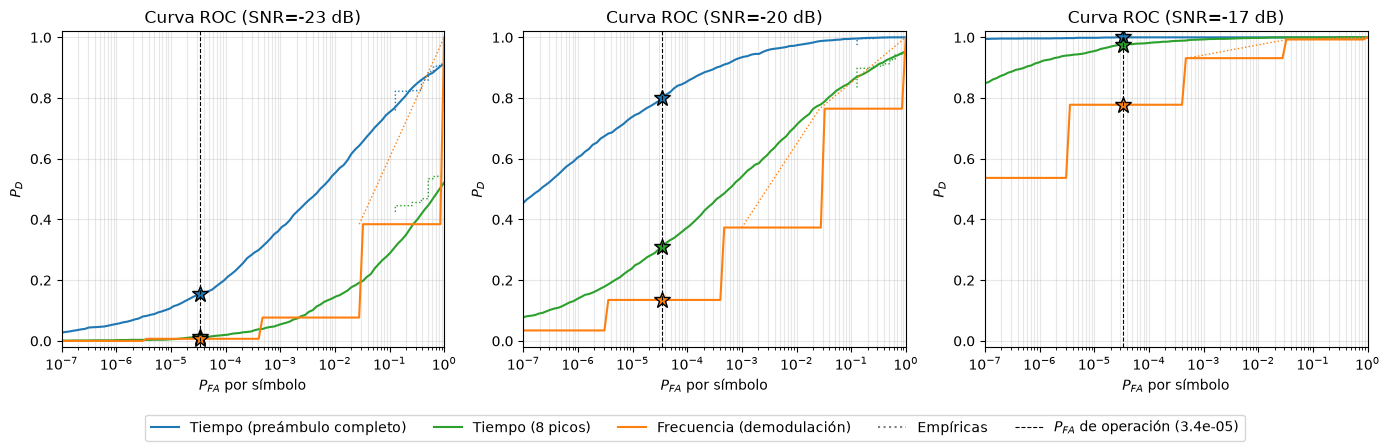

In [35]:
SNRs_roc_dB = [-23.0, -20.0, -17.0]  # Un gráfico por SNR, en el rango donde cambia la detección
simulaciones_roc = 2000  # Realizaciones por hipótesis
P_FA_eje = np.logspace(-7, 0, 100)  # P_FA por símbolo

curvas = {SNR: curvas_roc(SF, B, SNR, simulaciones_roc, P_FA_eje, P_FA) for SNR in SNRs_roc_dB}
graficar_roc(curvas, P_FA_eje, P_FA);

**Observaciones**:
- En el punto de operación, a $-20$ dB, la correlación con el preámbulo completo detecta con $P_D \approx 0.8$, la búsqueda de 8 picos con $\approx 0.3$ y la demodulación con $\approx 0.13$. La correlación con el preámbulo completo queda por encima de las demás para cualquier $P_{FA}$ y SNR.
- Entre la búsqueda de 8 picos y la demodulación el orden depende de la $P_{FA}$. Con $P_{FA}$ altas y SNR bajo la demodulación puede superar a la búsqueda de 8 picos, porque prueba una sola posición por símbolo y necesita un umbral más bajo para la misma tasa de falsas alarmas.
- En la demodulación la $P_D$ cae a escalones: con 9 umbrales posibles, la $P_{FA}$ de operación obliga a $K = 3$.
- El test en una posición funciona a menor SNR que la detección del inicio (a $-20$ dB, la correlación con el preámbulo completo tiene $P_D \approx 0.8$ pero un FER de $\approx 0.4$), porque encontrar el inicio exige además que la posición correcta supere a las vecinas.

## Prueba en el SDR

Hasta acá el receptor se evaluó por simulación. En este capítulo se prueba con un SDR (*software defined radio*), un equipo que transmite y recibe las muestras que genera y procesa la PC, en tres pasos:

1. **Loopback digital**: el SDR devuelve las muestras transmitidas sin pasar por el canal, y se verifica el software sin ruido.
2. **SNR y FER según la atenuación del TX**: se mide el SNR del equipo con distintas potencias de transmisión, para saber si llega al rango donde cambia el FER.
3. **FER por el aire**: se baja la señal hasta que la limite el ruido térmico del RX, y se compara el FER medido con la simulación.

Se usa un solo detector, la correlación con el preámbulo completo, que fue el de menor FER en la simulación (ver *Frame Error Rate (FER)*).

### Configuración del experimento

El SDR es un ADALM-Pluto del laboratorio, al que se accede por una VPN. El mismo equipo transmite (TX) y recibe (RX), así que ambos comparten el oscilador local y la señal llega sin corrimiento de frecuencia.

Se usan los mismos parámetros que en la sección del FER, $SF = 8$ y tramas de 10 símbolos de *payload*, con una portadora de 905 MHz. El ancho de banda es $B = 1$ MHz, con una muestra por chip, dentro del rango de muestreo del Pluto (de 521 kHz a 61.44 MHz según el material del laboratorio). Como el SNR de la simulación es por muestra, la curva de FER vs SNR no depende de $B$, y el resultado vale también para los 125 kHz de LoRa.

El TX repite sin pausa un buffer de varias tramas, 50 para medir el SNR y 200 para el FER. Antes de cada trama hay un silencio de largo al azar, de 5 a 10 símbolos, para que el receptor no pueda predecir dónde empieza la siguiente. El RX graba una captura que contiene todas las tramas del buffer.

El receptor recorre la captura sin saber dónde están las tramas. En cada tramo busca un preámbulo con el detector y, si lo encuentra, estima el inicio de la trama. El umbral del detector se calcula con la potencia del ruido medida en los silencios, como si el receptor la estimara mientras el canal está libre. La medición, que sí conoce lo transmitido, ubica el buffer en la captura y compara el inicio real de cada trama con el inicio detectado más cercano. Los detalles de la transmisión y del recorrido de la captura están en *Anexo B: transmisión y recepción de las tramas*.

In [ ]:
# False: usa las capturas guardadas en captures/ (no necesita el SDR ni la VPN)
# True: mide con el SDR del laboratorio y sobrescribe captures/
USAR_SDR = False
URI = "ip:192.168.1.32" if USAR_SDR else None

SF_sdr = 8
B_sdr = 1e6  # Ancho de banda y frecuencia de muestreo del SDR
n_simbolos = 10  # Símbolos del payload
rango_silencio = (5, 10)  # Largo del silencio antes de cada trama, en símbolos
P_FA_sdr = 1 / 60 * 2**SF_sdr / B_sdr  # Una falsa alarma por minuto
N_TRAMAS = 200  # Tramas por punto del FER
RANGO_FER_dB = np.array([-22.0, -10.0])  # Donde el FER simulado pasa de 1 a 10^-3

In [ ]:
# Conexión con el ADALM-Pluto. La biblioteca pyadi-iio (adi) solo hace falta con USAR_SDR = True.
# Los atributos del Pluto (sample_rate, tx_lo, rx(), ...) son los nombres de pyadi-iio

FRECUENCIA_LO = 905e6  # Portadora
ATENUACION_TX_dB = -10  # Atenuación del TX al conectar
RANGO_ATENUACION_TX_dB = (-89, -3)  # Con menos de 3 dB de atenuación se puede dañar el receptor

ESCALA_TX = 2**14  # Pico de I y Q del TX: pyadi espera muestras en ±2^14
FONDO_DE_ESCALA_ADC = 2**11  # El ADC del AD9363 es de 12 bits: muestras en ±2048
OBJETIVO_AGC_dB = -11  # Valor eficaz que busca el AGC slow_attack, en dB del fondo de escala
PISO_RUIDO_ADC = 1 / 6  # Ruido de cuantización complejo, 2 Δ²/12 con Δ = 1

DESCARTE = 5  # Buffers del RX descartados después de cambiar el TX. Subir si FER = 1 en loopback
ASENTAMIENTO_AGC = 15  # Buffers para que el AGC converja. Subir si la ganancia elegida varía
LARGO_DESCARTE = 2**13  # Muestras de los buffers descartados: cortos, para no traerlos por la VPN


"""
Fija la atenuación del TX; da error si está fuera de RANGO_ATENUACION_TX_dB.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
        atenuacion_dB: Atenuación, en dB (negativa).
"""

def fijar_atenuacion_tx(pluto, atenuacion_dB: float) -> None:

    # Atenuación del TX, en dB (negativa). La potencia máxima del TX es 10 dBm: con -10 dB
    # transmite 0 dBm (1 mW). Rechaza valores fuera de RANGO_ATENUACION_TX_dB
    minima, maxima = RANGO_ATENUACION_TX_dB
    if not minima <= atenuacion_dB <= maxima:
        raise ValueError(f"Atenuación del TX fuera de [{minima}, {maxima}] dB: {atenuacion_dB}")
    pluto.tx_hardwaregain_chan0 = float(atenuacion_dB)  # pyadi rechaza los enteros de numpy


"""
Deja el SDR sin interferir: máxima atenuación, TX y RX separados y TX en ceros.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
"""

def liberar(pluto) -> None:

    # Deja el SDR sin interferir: máxima atenuación, TX y RX en frecuencias distintas y TX en
    # ceros. El TX del Pluto no se puede apagar
    pluto.tx_destroy_buffer()
    fijar_atenuacion_tx(pluto, RANGO_ATENUACION_TX_dB[0])
    pluto.tx_lo = int(2400e6)
    pluto.rx_lo = int(950e6)
    pluto.tx(np.zeros(2048, dtype=complex))


"""
Abre y configura el Pluto para usarlo con `with`; al salir, lo libera.

    Parámetros:
        uri: Dirección del SDR, por ejemplo 'ip:192.168.1.32'.
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        loopback: 0 = por el aire, 1 = loopback digital.

    Devuelve:
        El SDR configurado, en `with sesion(...) as pluto`.
"""

@contextmanager
def sesion(uri: str, B: float, loopback: int):

    # Abre el Pluto y lo configura para transmitir y recibir tramas, con el RX en control
    # automático de ganancia. Se usa con `with sesion(...) as pluto:`, y al salir del bloque,
    # aunque haya un error, lo libera. loopback: 0 = por el aire, 1 = loopback digital (no pasa
    # por el ADC ni el DAC)
    import adi

    pluto = adi.Pluto(uri)
    pluto.loopback = loopback
    pluto.sample_rate = int(B)
    pluto.tx_rf_bandwidth = int(B)
    pluto.rx_rf_bandwidth = int(B)
    pluto.tx_lo = int(FRECUENCIA_LO)
    pluto.rx_lo = int(FRECUENCIA_LO)
    fijar_atenuacion_tx(pluto, ATENUACION_TX_dB)
    pluto.gain_control_mode_chan0 = "slow_attack"
    pluto.tx_cyclic_buffer = True
    try:
        yield pluto
    finally:
        liberar(pluto)


"""
Pluto ideal para probar sin hardware: canal plano, sin ruido, con el ADC saturado.
"""

class PlutoSimulado:

    # Pluto ideal, para probar sin hardware: rx() devuelve el buffer del TX repetido a partir de
    # una muestra al azar (canal plano, sin ruido propio ni corrimiento de frecuencia), saturado y
    # cuantizado como en el ADC. Con la ganancia GANANCIA_REF_dB el pico del TX llega a la mitad
    # del fondo de escala, como en el loopback digital del Pluto. En "slow_attack" la ganancia
    # lleva el valor eficaz a OBJETIVO_AGC_dB, como el AGC
    GANANCIA_REF_dB = 30.0
    rx_buffer_size = 0
    rx_hardwaregain_chan0 = GANANCIA_REF_dB
    gain_control_mode_chan0 = "manual"

    """
    Guarda el buffer que transmite el TX.

        Parámetros:
            x: Muestras a transmitir.
    """

    def tx(self, x):

        self.x = x

    """
    Captura rx_buffer_size muestras del buffer repetido, como las da el ADC.

        Devuelve:
            La captura.
    """

    def rx(self):

        if self.gain_control_mode_chan0 == "slow_attack":
            potencia_tx_dB = 10 * np.log10(potencia(self.x) / (2 * ESCALA_TX) ** 2)
            ganancia_dB = self.GANANCIA_REF_dB + OBJETIVO_AGC_dB - potencia_tx_dB
            self.rx_hardwaregain_chan0 = round(ganancia_dB)

        # El buffer repetido desde una muestra al azar, escalado por la ganancia del RX
        r = np.resize(np.roll(self.x, rng.integers(self.x.size)), self.rx_buffer_size)
        ganancia = 10 ** ((self.rx_hardwaregain_chan0 - self.GANANCIA_REF_dB) / 20)
        r = np.round(r * FONDO_DE_ESCALA_ADC / (2 * ESCALA_TX) * ganancia)

        # Saturación del ADC
        minimo, maximo = -FONDO_DE_ESCALA_ADC, FONDO_DE_ESCALA_ADC - 1
        return np.clip(np.real(r), minimo, maximo) + 1j * np.clip(np.imag(r), minimo, maximo)

    """
    No hace nada: está para tener los métodos del Pluto.
    """

    def tx_destroy_buffer(self):

        pass

    """
    No hace nada: está para tener los métodos del Pluto.
    """

    def rx_destroy_buffer(self):

        pass

In [ ]:
# Transmisión y captura de tramas con el SDR. Las claves de los metadatos ("symbols", "gaps",
# "gain", ...) son las de los archivos de captures/


"""
Arma el buffer del TX: cada trama con su silencio, preámbulo y payload.

    Parámetros:
        simbolos: Payload de cada trama, una fila por trama.
        silencios: Muestras de silencio antes de cada trama.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Las muestras del buffer, sin ruido.
"""

def buffer_de_tramas(simbolos: np.ndarray, silencios: np.ndarray, SF: int, B: float) -> np.ndarray:

    # Buffer del TX sin ruido: una trama por fila de `simbolos`, cada una con su silencio (en
    # muestras) antes del preámbulo
    chirps = tabla_de_chirps(SF, B)
    partes = []
    for simbolos_trama, silencio in zip(simbolos, silencios):
        partes.append(np.zeros(silencio))
        partes.append(preambulo(SF, B))
        for s in simbolos_trama:
            partes.append(chirps[s])
    return np.concatenate(partes)


"""
Mayor valor absoluto de I y Q.

    Parámetros:
        x: Señal.

    Devuelve:
        El pico.
"""

def pico_adc(x: np.ndarray) -> float:

    # Mayor valor absoluto de I y Q
    return float(max(np.abs(x.real).max(), np.abs(x.imag).max()))


"""
Transmite x en forma cíclica y captura n_muestras muestras.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
        x: Buffer a transmitir.
        n_muestras: Largo de la captura.
        calibrar: Fijar la ganancia del RX con el AGC antes de capturar.
        escala_dB: Escala del TX respecto del pico ESCALA_TX, en dB.

    Devuelve:
        La captura y la ganancia del RX, en dB.
"""

def grabar(
    pluto, x: np.ndarray, n_muestras: int, calibrar: bool = True, escala_dB: float = 0.0
) -> tuple[np.ndarray, float]:

    # Transmite x en forma cíclica y captura n_muestras muestras de la señal nueva. Devuelve la
    # captura y la ganancia del RX, en dB. Si `calibrar`, deja actuar al control automático de
    # ganancia (AGC) y después fija la ganancia que eligió: con el AGC activo, el silencio y la
    # trama se recibirían con ganancias distintas
    pluto.tx_destroy_buffer()
    pluto.rx_destroy_buffer()
    pluto.rx_buffer_size = LARGO_DESCARTE
    pluto.tx(x / pico_adc(x) * ESCALA_TX * 10 ** (escala_dB / 20))

    if calibrar:
        pluto.gain_control_mode_chan0 = "slow_attack"
        for _ in range(ASENTAMIENTO_AGC):
            pluto.rx()
        ganancia = pluto.rx_hardwaregain_chan0
        pluto.gain_control_mode_chan0 = "manual"
        pluto.rx_hardwaregain_chan0 = ganancia

    for _ in range(DESCARTE):  # Buffers con la señal anterior
        pluto.rx()
    pluto.rx_destroy_buffer()
    pluto.rx_buffer_size = n_muestras
    return pluto.rx(), pluto.rx_hardwaregain_chan0


"""
Transmite y captura un buffer de tramas con payloads y silencios al azar.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        n_tramas: Tramas del buffer.
        n_simbolos: Símbolos del payload por trama.
        rango_silencio: Silencio mínimo y máximo antes de cada trama, en símbolos.
        calibrar: Fijar la ganancia del RX con el AGC antes de capturar.
        escala_dB: Escala del TX respecto del pico ESCALA_TX, en dB.

    Devuelve:
        Símbolos, silencios (en muestras), captura y ganancia del RX.
"""

def medir(
    pluto,
    SF: int,
    B: float,
    n_tramas: int,
    n_simbolos: int,
    rango_silencio: tuple[int, int],
    calibrar: bool = True,
    escala_dB: float = 0.0,
):

    # Transmite un buffer de n_tramas tramas con payloads y silencios al azar, y lo captura.
    # Devuelve los símbolos (n_tramas, n_simbolos), los silencios en muestras, la captura y la
    # ganancia del RX. Cada silencio dura entre rango_silencio[0] y rango_silencio[1] símbolos:
    # el receptor no puede predecir dónde empieza la trama siguiente. escala_dB baja la señal del
    # TX respecto del pico ESCALA_TX sin bajar el ruido del RX
    N = 2**SF
    simbolos = rng.integers(0, N, size=(n_tramas, n_simbolos))
    silencios = rng.integers(rango_silencio[0] * N, rango_silencio[1] * N, size=n_tramas)
    # Con un buffer de largo impar el TX del Pluto agrega una muestra en cada repetición
    silencios[0] += silencios.sum() % 2  # El preámbulo y el payload tienen largo par
    x = buffer_de_tramas(simbolos, silencios, SF, B)

    # La captura tiene el buffer completo y por lo menos tres períodos más (silencio y trama),
    # para que cada trama aparezca entera al menos una vez después de los dos primeros (evaluar).
    # Su largo no depende de los silencios, así que las capturas se pueden apilar
    mas_larga = rango_silencio[1] * N + preambulo(SF, B).size + n_simbolos * N
    r, ganancia = grabar(pluto, x, (n_tramas + 3) * mas_larga, calibrar, escala_dB)
    return simbolos, silencios, r, ganancia


"""
Junta las salidas de medir de un barrido en capturas y metadatos.

    Parámetros:
        corridas: Salidas de medir, una por punto del barrido.
        meta: Metadatos adicionales del barrido.

    Devuelve:
        Las capturas y un diccionario con los metadatos.
"""

def apilar(corridas: list, **meta) -> tuple[np.ndarray, dict]:

    # Junta las salidas de medir de un barrido, una por punto, en capturas y metadatos
    simbolos, silencios, capturas, ganancias = map(np.array, zip(*corridas))
    return capturas, {"symbols": simbolos, "gaps": silencios, "gain": ganancias, **meta}


"""
Guarda capturas y metadatos en un archivo .npz.

    Parámetros:
        ruta: Archivo.
        capturas: Capturas complejas.
        meta: Metadatos.
"""

def guardar_capturas(ruta: str, capturas: np.ndarray, **meta) -> None:

    # Guarda capturas y metadatos en un .npz. Las muestras del ADC son enteras: van en int16
    iq = np.stack([np.real(capturas), np.imag(capturas)], axis=-1).round().astype(np.int16)
    Path(ruta).parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(ruta, iq=iq, **meta)


"""
Carga un archivo .npz de guardar_capturas.

    Parámetros:
        ruta: Archivo.

    Devuelve:
        Las capturas y los metadatos.
"""

def cargar_capturas(ruta: str) -> tuple[np.ndarray, dict]:

    # Carga un .npz de guardar_capturas: capturas complejas y metadatos
    with np.load(ruta) as archivo:
        datos = dict(archivo)
    iq = datos.pop("iq").astype(float)
    return iq[..., 0] + 1j * iq[..., 1], datos


"""
Mide con el SDR y guarda las capturas, o carga las guardadas.

    Parámetros:
        ruta: Archivo de las capturas.
        medicion: Función medicion(pluto) que devuelve capturas y metadatos.
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        uri: Dirección del SDR, o None para no usarlo.
        loopback: 0 = por el aire, 1 = loopback digital.

    Devuelve:
        Las capturas y los metadatos.
"""

def adquirir(
    ruta: str, medicion, B: float, uri: str | None, loopback: int = 0
) -> tuple[np.ndarray, dict]:

    # Capturas de un paso del experimento y sus metadatos. Con `uri`, mide con el SDR
    # (medicion(pluto) devuelve capturas y metadatos) y las guarda en `ruta`. Sin `uri`, carga las
    # guardadas o, si no hay, mide con PlutoSimulado sin guardar
    if uri is not None:
        with sesion(uri, B, loopback) as pluto:
            capturas, meta = medicion(pluto)
        guardar_capturas(ruta, capturas, **meta)
    elif not Path(ruta).exists():
        print(f"Sin {ruta}: Pluto simulado (canal plano, sin ruido ni distorsión del equipo)")
        return medicion(PlutoSimulado())
    return cargar_capturas(ruta)

In [ ]:
# Recepción y medición de las capturas (no necesita el SDR)


"""
Receptor: busca las tramas en una captura sin saber dónde están.

    Parámetros:
        r: Captura.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.
        n_simbolos: Símbolos del payload por trama.

    Devuelve:
        La muestra de inicio de cada trama detectada.
"""

def recibir(
    r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float, n_simbolos: int
) -> np.ndarray:

    # Receptor: busca las tramas en una captura sin saber dónde están y devuelve la muestra de
    # inicio de cada una. Recorre la captura con una ventana de dos tramas de largo y busca un
    # preámbulo en ella. Si lo encuentra, la ventana siguiente empieza donde termina la trama. Si
    # no, avanza una trama: una trama que empieza en la primera mitad de la ventana entra entera en
    # ella, y la que empieza en la segunda mitad, en la ventana siguiente
    N = 2**SF
    largo_trama = preambulo(SF, B).size + n_simbolos * N

    # La primera ventana empieza en el símbolo de menor energía de las dos primeras tramas de
    # largo, que con SNR alto cae en un silencio: si empezara a mitad de un payload, podría
    # confundir sus chirps con el preámbulo
    energia = np.convolve(np.abs(r[: 2 * largo_trama]) ** 2, np.ones(N), "valid")
    pos = int(np.argmin(energia))

    inicios = []
    while r.size - pos >= largo_trama:
        ventana = r[pos : pos + 2 * largo_trama]
        inicio = detectar_preambulo_completo(ventana, SF, B, sigma2, P_FA)
        if inicio is None:
            pos += largo_trama
            continue
        pos += inicio + largo_trama
        if pos > r.size:
            break  # Trama cortada al final de la captura
        inicios.append(pos - largo_trama)
    return np.array(inicios, dtype=int)


"""
Estima el SNR de una captura alineada con el buffer transmitido.

    Parámetros:
        r: Captura alineada con x.
        x: Buffer transmitido, sin ruido.

    Devuelve:
        El SNR, en dB.
"""

def snr_medido(r: np.ndarray, x: np.ndarray) -> float:

    # SNR de una captura r alineada con el buffer transmitido sin ruido x, respecto de la potencia
    # de la trama (como en la simulación). Se estima por mínimos cuadrados la amplitud compleja de
    # la señal recibida (ganancia y fase del canal), y lo que queda al restarla es el ruido,
    # incluida la distorsión del equipo
    a = np.vdot(x, r) / np.vdot(x, x)
    ruido = max(potencia(r - a * x), PISO_RUIDO_ADC)
    return float(10 * np.log10(np.abs(a) ** 2 * potencia(x[x != 0]) / ruido))


"""
Resultado de evaluar una captura.
"""

class Evaluacion(NamedTuple):

    # Resultado de evaluar una captura
    errores: np.ndarray  # Por trama transmitida: inicio no detectado en la muestra exacta
    error_inicio: np.ndarray  # Inicio detectado menos inicio real, en muestras, de las detectadas
    snr: float  # SNR medido, en dB
    inicios: np.ndarray  # Inicios detectados por el receptor, en muestras de la captura


"""
Pasa una captura por el receptor y la compara con lo transmitido.

    Parámetros:
        r: Captura de medir.
        simbolos: Símbolos transmitidos, una fila por trama.
        silencios: Silencio antes de cada trama, en muestras.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        Errores, error del inicio, SNR e inicios detectados.
"""

def evaluar(
    r: np.ndarray, simbolos: np.ndarray, silencios: np.ndarray, SF: int, B: float, P_FA: float
) -> Evaluacion:

    # Pasa una captura de medir por el receptor y la compara con lo transmitido. El receptor no
    # sabe dónde están las tramas; la medición sí: ubica el buffer transmitido en la captura con el
    # máximo de la correlación circular, y de ahí sale el inicio real de cada trama
    N = 2**SF
    n_simbolos = simbolos.shape[1]
    x = buffer_de_tramas(simbolos, silencios, SF, B)
    L = x.size
    largo_trama = preambulo(SF, B).size + n_simbolos * N
    mas_larga = silencios.max() + largo_trama

    # Inicio de cada trama en el buffer: los silencios hasta ella inclusive y las tramas anteriores
    en_buffer = np.cumsum(silencios) + np.arange(len(silencios)) * largo_trama
    # Retardo de la captura: la muestra i del buffer está en la muestra (i + retardo) mod L
    correlacion_circular = np.fft.ifft(np.fft.fft(r[:L]) * np.conj(np.fft.fft(x)))
    retardo = int(np.argmax(np.abs(correlacion_circular)))
    # Inicio real de cada trama, una vez cada una, después de los dos primeros períodos más
    # largos: el receptor se sincroniza en ellos y puede perder alguna trama
    reales = 2 * mas_larga + (en_buffer + retardo - 2 * mas_larga) % L

    # La potencia del ruido se estima en el silencio antes de cada trama, donde solo hay ruido
    silencios_rx = [r[real - silencio : real] for real, silencio in zip(reales, silencios)]
    ruido = max(potencia(np.concatenate(silencios_rx)), PISO_RUIDO_ADC)

    inicios = recibir(r, SF, B, ruido, P_FA, n_simbolos)
    snr = snr_medido(np.roll(r[:L], -retardo), x)
    if inicios.size == 0:
        return Evaluacion(np.ones(len(simbolos), dtype=bool), inicios, snr, inicios)

    # Cada trama transmitida se compara con la detección más cercana a su inicio real
    mas_cercana = np.abs(inicios[:, None] - reales).argmin(axis=0)
    error_inicio = inicios[mas_cercana] - reales
    encontradas = np.abs(error_inicio) < largo_trama // 2
    return Evaluacion(error_inicio != 0, error_inicio[encontradas], snr, inicios)


"""
Evalúa cada captura de un barrido.

    Parámetros:
        capturas: Capturas de apilar.
        meta: Metadatos de apilar.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        Una Evaluacion por captura.
"""

def evaluar_todas(
    capturas: np.ndarray, meta: dict, SF: int, B: float, P_FA: float
) -> list[Evaluacion]:

    # evaluar para cada captura de apilar
    evaluaciones = []
    for r, simbolos, silencios in zip(capturas, meta["symbols"], meta["gaps"]):
        evaluaciones.append(evaluar(r, simbolos, silencios, SF, B, P_FA))
    return evaluaciones

### Loopback digital

En loopback digital, el Pluto devuelve al RX las muestras del TX sin convertirlas en una señal analógica, así que no hay ruido ni canal. Se espera detectar el inicio de todas las tramas en la muestra exacta, y cualquier error indica una falla del software.

In [ ]:
"""
Mide 10 tramas en loopback digital, sin calibrar la ganancia.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        La captura y los metadatos.
"""

def medir_loopback(pluto):

    simbolos, silencios, r, _ = medir(
        pluto, SF_sdr, B_sdr, 10, n_simbolos, rango_silencio, calibrar=False
    )
    return r, {"symbols": simbolos, "gaps": silencios}


r_loop, meta_loop = adquirir("captures/loopback.npz", medir_loopback, B_sdr, URI, loopback=1)
ev_loop = evaluar(r_loop, meta_loop["symbols"], meta_loop["gaps"], SF_sdr, B_sdr, P_FA_sdr)
print(f"Loopback digital: {ev_loop.errores.sum()} de {ev_loop.errores.size} tramas perdidas")

**Observaciones**:
- Las 10 tramas se detectan con el inicio en la muestra exacta, así que el armado de las tramas, la escala de las muestras, el manejo de los buffers y el receptor funcionan.

### SNR y FER según la atenuación del TX

En la simulación, el FER pasa de casi 1 a casi 0 entre $-22$ y $-10$ dB de SNR (ver *Frame Error Rate (FER)*). Para saber si el equipo llega a ese rango, se transmiten 50 tramas con cada atenuación del TX y se miden el SNR y el FER. La ganancia del RX la elige el control automático de ganancia (AGC) del Pluto antes de cada captura, y después queda fija para que el silencio, donde se estima la potencia del ruido para el umbral, y la trama se reciban con la misma ganancia (ver *Anexo B: fondo de escala del ADC*).

El SNR se estima comparando la captura con lo transmitido. Con el buffer transmitido $x$ y la captura $r$ alineada con él, ambos de $N$ muestras, la amplitud compleja $\hat a$ con que llega la señal se estima por mínimos cuadrados, y lo que queda al restar la señal es el ruido:

$$
\hat a = \frac{\langle x, r \rangle}{\langle x, x \rangle}, \qquad
\hat\sigma^2 = \frac{\| r - \hat a\, x \|^2}{N}, \qquad
SNR = \frac{|\hat a|^2 P_{trama}}{\hat\sigma^2}
$$

donde $P_{trama}$ es la potencia de la trama, la misma referencia que en la simulación. El ruido estimado $\hat\sigma^2$ incluye el ruido térmico del RX, la cuantización y la distorsión del equipo, todo lo que no es la señal transmitida.

Si el SNR queda por encima del rango aun con la máxima atenuación, hace falta bajar la señal de otra forma.

In [ ]:
ATENUACIONES_dB = np.array([-10.0, -30.0, -50.0, -70.0, -89.0])


"""
Mide 50 tramas con cada atenuación del TX de ATENUACIONES_dB.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        Las capturas y los metadatos.
"""

def medir_atenuaciones(pluto):

    corridas = []
    for atenuacion_dB in ATENUACIONES_dB:
        fijar_atenuacion_tx(pluto, atenuacion_dB)
        corridas.append(medir(pluto, SF_sdr, B_sdr, 50, n_simbolos, rango_silencio))
    return apilar(corridas, attens_dB=ATENUACIONES_dB)


"""
Grafica el SNR medido vs la atenuación del TX, con el rango del FER.

    Parámetros:
        atenuaciones_dB: Atenuaciones del TX.
        snr_dB: SNR medido con cada atenuación.
        rango_fer_dB: SNR donde el FER simulado pasa de casi 1 a casi 0.

    Devuelve:
        La figura.
"""

def graficar_snr_vs_atenuacion(
    atenuaciones_dB: np.ndarray, snr_dB: np.ndarray, rango_fer_dB: np.ndarray
):

    # SNR medido vs atenuación del TX, junto con el rango de SNR donde el FER simulado pasa de casi
    # 1 a casi 0
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.axhspan(min(rango_fer_dB), max(rango_fer_dB), color="C1", alpha=0.2, label="Rango del FER")
    ax.plot(atenuaciones_dB, snr_dB, "o-", label="SNR medido")
    ax.set(
        title="SNR según la atenuación del TX", xlabel="Atenuación del TX [dB]", ylabel="SNR [dB]"
    )
    ax.grid(True)
    ax.legend()
    fig.tight_layout()
    return fig


c_att, meta_att = adquirir("captures/atten.npz", medir_atenuaciones, B_sdr, URI)
evs_att = evaluar_todas(c_att, meta_att, SF_sdr, B_sdr, P_FA_sdr)
for atenuacion_dB, ganancia, ev in zip(meta_att["attens_dB"], meta_att["gain"], evs_att):
    print(
        f"Atenuación {atenuacion_dB:4.0f} dB: ganancia {ganancia:2.0f} dB, SNR {ev.snr:5.1f} dB, "
        f"FER {ev.errores.mean():.2f}"
    )
snr_att = np.array([ev.snr for ev in evs_att])
graficar_snr_vs_atenuacion(meta_att["attens_dB"], snr_att, RANGO_FER_dB);

**Observaciones**:
- El SNR queda entre 11 y 16 dB con cualquier atenuación del TX. Entre $-30$ y $-70$ dB casi no cambia ($\approx 14$ dB), porque el AGC sube la ganancia lo mismo que baja la señal y lo que limita el SNR es proporcional a la señal, como la distorsión del equipo, y no el ruido del receptor. Con $-89$ dB la ganancia llega a su máximo (73 dB) y el ruido del receptor empieza a pesar.
- El SNR nunca llega al rango donde cambia el FER, de $-22$ a $-10$ dB, porque con la atenuación máxima harían falta más de 20 dB de pérdida adicional. Como $-89$ dB es la máxima atenuación del TX, la señal se baja reduciendo la amplitud de las muestras (ver *FER por el aire*).
- Las 250 tramas se detectan con el inicio exacto, como en la simulación con SNR alto. Con SNR alto la cola de cada trama supera el umbral apenas termina, y el primer cruce puede llegar más de 8 símbolos antes del preámbulo siguiente, por eso el detector sigue el máximo después del cruce (ver *Detección en el tiempo: correlación con el preámbulo completo*).

### FER por el aire

Para medir el FER en el rango de la simulación, la señal tiene que llegar por debajo del ruido. Ese ruido tiene que ser el térmico del RX, que es gaussiano y es el que limita a un receptor real cuando la señal llega débil.

Con la máxima atenuación del TX la señal todavía llega por encima del ruido (ver *SNR y FER según la atenuación del TX*). Por eso se mantiene esa atenuación y además se multiplican las muestras por una escala de $-22$ a $-36$ dB antes de transmitirlas. La señal baja y el ruido del RX no cambia. La atenuación tiene que ser la máxima porque el TX también emite su propio ruido y la fuga de su oscilador local, que la escala no reduce y que tienen que llegar por debajo del ruido del RX.

Que la señal quede por debajo del ruido no es un problema para el ADC mientras el ruido ocupe varios niveles, porque entonces la cuantización agrega poco frente a él. Otra forma de llegar al rango del FER sería sumar ruido blanco gaussiano a las muestras antes de transmitirlas, con el mismo modelo que la simulación. No se usa porque ese ruido se genera en la PC y no es el que limita a un receptor real.

El FER medido se compara con el simulado en el canal plano, con el mismo detector y los mismos parámetros. Se espera que los puntos queden sobre la curva simulada, porque en el laboratorio las reflexiones recorren a lo sumo algunos metros más que el camino directo, unas decenas de ns, mucho menos que un chip de 1 µs, y el canal se comporta como plano. Si quedaran a la derecha (más SNR para el mismo FER), la diferencia sería una pérdida del equipo real. Con 200 tramas por punto, el menor FER que se puede medir es $1/200 = 5 \cdot 10^{-3}$. Un punto sin errores no entra en la escala logarítmica, y se dibuja en ese valor como cota superior.

In [ ]:
# Escala digital del TX, con la máxima atenuación: lleva el SNR al rango del FER
ESCALAS_dB = np.arange(-36.0, -21.0, 2.0)


"""
Mide N_TRAMAS tramas con cada escala de ESCALAS_dB y la máxima atenuación.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        Las capturas y los metadatos.
"""

def medir_ruido_termico(pluto):

    fijar_atenuacion_tx(pluto, RANGO_ATENUACION_TX_dB[0])
    corridas = []
    for escala_dB in ESCALAS_dB:
        corrida = medir(
            pluto, SF_sdr, B_sdr, N_TRAMAS, n_simbolos, rango_silencio, escala_dB=escala_dB
        )
        corridas.append(corrida)
    return apilar(corridas, scales_dB=ESCALAS_dB)


c_termica, meta_termica = adquirir("captures/thermal.npz", medir_ruido_termico, B_sdr, URI)
evs_termica = evaluar_todas(c_termica, meta_termica, SF_sdr, B_sdr, P_FA_sdr)
for escala_dB, ganancia, r, ev in zip(
    meta_termica["scales_dB"], meta_termica["gain"], c_termica, evs_termica
):
    no_detectadas = ev.errores.size - ev.error_inicio.size
    print(
        f"Escala {escala_dB:5.1f} dB: SNR medido {ev.snr:5.1f} dB, ganancia {ganancia:2.0f} dB, "
        f"valor eficaz {np.sqrt(potencia(r)):4.0f} niveles del ADC, "
        f"FER {ev.errores.mean():.3f} ({no_detectadas} no detectadas)"
    )

error_inicio = np.concatenate([ev.error_inicio for ev in evs_termica])
valores, cantidades = np.unique(error_inicio, return_counts=True)
print(
    "Error del inicio detectado (muestras: tramas):",
    dict(zip(valores.tolist(), cantidades.tolist())),
)

In [ ]:
"""
Grafica el FER medido con el SDR sobre el FER simulado.

    Parámetros:
        SNRs_sim_dB: SNR simulados, en dB.
        fer_sim: FER simulado de cada SNR.
        snr: SNR medido de cada punto del SDR.
        fer: FER medido de cada punto del SDR.
        n_tramas: Tramas medidas por punto.

    Devuelve:
        La figura.
"""

def graficar_fer_sdr(
    SNRs_sim_dB: np.ndarray, fer_sim: np.ndarray, snr: np.ndarray, fer: np.ndarray, n_tramas: int
):

    # FER medido con el SDR sobre la curva simulada en canal plano. Los puntos sin errores no
    # entran en la escala logarítmica: se dibujan en 1 / n_tramas, el menor FER que se puede
    # medir, como cota superior
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(SNRs_sim_dB, fer_sim, label="Simulación (canal plano)")
    ax.plot(snr[fer > 0], fer[fer > 0], "o", color="C1", label="SDR")
    sin_errores = fer == 0
    if np.any(sin_errores):
        ax.plot(
            snr[sin_errores],
            np.full(np.sum(sin_errores), 1 / n_tramas),
            "v",
            color="C1",
            mfc="none",
            label=f"SDR, sin errores en {n_tramas} tramas",
        )
    ax.set_yscale("log", nonpositive="mask")
    snrs = np.concatenate([SNRs_sim_dB, snr])
    ax.set_xlim(snrs.min() - 0.5, snrs.max() + 0.5)
    ax.set(title="FER: simulación y SDR", xlabel="SNR [dB]", ylabel="FER")
    ax.grid(True, which="both", alpha=0.5)
    ax.legend()
    fig.tight_layout()
    return fig


# Referencia: FER simulado en canal plano con el mismo detector y los mismos parámetros
SNRs_sim_dB = np.arange(-24.0, -7.0, 1.0)
fer_sim = fer_vs_snr(
    detectar_preambulo_completo,
    SNRs_sim_dB,
    CANAL_PLANO,
    SF_sdr,
    B_sdr,
    P_FA_sdr,
    2000,
    n_simbolos,
    rango_silencio[0],
    min_errores=30,
)
snr_termica = np.array([ev.snr for ev in evs_termica])
fer_termica = np.array([ev.errores.mean() for ev in evs_termica])
graficar_fer_sdr(SNRs_sim_dB, fer_sim, snr_termica, fer_termica, N_TRAMAS);

**Observaciones**:
- El SNR medido baja lo mismo que la escala, de $\approx -23$ a $\approx -9$ dB, mientras la ganancia del RX queda en su máximo (73 dB) y el valor eficaz de la captura en 15 niveles del ADC en todos los puntos. El ruido no cambia con la señal, por lo que es el del RX, y ocupa decenas de niveles, así que la cuantización del ADC no pesa.
- El FER medido sigue la curva simulada en todo el rango, de $\approx 0.9$ a $-23$ dB a $0.01$ a $-12$ dB, con puntos a ambos lados de la curva. Las diferencias, como 0.04 contra $\approx 0.08$ cerca de $-16$ dB, son del orden de la dispersión de 200 tramas por punto, y desde $-10$ dB no se pierde ninguna trama. El ruido térmico del RX se comporta como el ruido blanco gaussiano de la simulación, y el equipo no agrega pérdidas al receptor.
- Las tramas no detectadas se concentran en $-23$ y $-21$ dB, y desde $-16$ dB se detectan todas. A partir de ese SNR las tramas perdidas son inicios corridos medio símbolo o un símbolo ($\pm 128$ y $\pm 256$ muestras, 101 de las 109 tramas corridas), por los picos laterales de $T[k]$, como en la simulación (ver *Frame Error Rate (FER)*).

## Anexo A: detección de una trama

### Falsas alarmas

En la detección del preámbulo, el detector declara $H_1$ en el primer cruce del umbral y toma como inicio el máximo del estadístico a partir de ese cruce. El silencio antes de la trama dura 5 símbolos, menos que el largo del preámbulo, así que una falsa alarma en el silencio queda corregida por el preámbulo que llega después y el FER casi no la muestra. Un receptor real, en cambio, pasa la mayor parte del tiempo escuchando solo ruido.

Para verificar que los umbrales de Neyman-Pearson cumplen la $P_{FA}$ pedida, se aplica cada método a 20000 símbolos de solo ruido y se mide la fracción de posiciones que superan el umbral. En el punto de operación la $P_{FA}$ por muestra de los métodos en el tiempo es $P_{FA}/2^{SF} \approx 1.3 \cdot 10^{-7}$, y harían falta del orden de $10^9$ muestras para observar suficientes falsas alarmas. Como la distribución bajo $H_0$ no depende del umbral, el cálculo se verifica en un rango medible, de $10^{-1}$ a $10^{-5}$ por posición. En frecuencia $V[m]$ es entero, y solo los umbrales $K = 1$ y $K = 2$ tienen una $P_{FA}$ medible, porque con $K = 3$ ($3.3 \cdot 10^{-6}$) se esperaría menos de una falsa alarma en 20000 ventanas.

In [ ]:
"""
Mide la P_FA de cada método sobre una señal larga de solo ruido.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        n_simbolos_ruido: Largo de la señal de ruido, en símbolos.
        P_FA_pedidas: P_FA por posición para los métodos en el tiempo.
        Ks: Umbrales a medir en frecuencia.

    Devuelve:
        Por método, la P_FA pedida y la medida.
"""

def falsas_alarmas_medidas(
    SF: int,
    B: float,
    n_simbolos_ruido: int,
    P_FA_pedidas: np.ndarray,
    Ks: tuple[int, ...] = (1, 2),
) -> dict[str, tuple[np.ndarray, np.ndarray]]:

    # Mide la P_FA de cada método sobre una señal larga de solo ruido (-10 dB): la fracción de
    # posiciones que superan el umbral debe coincidir con la P_FA pedida, por posición. En
    # frecuencia solo se miden los umbrales Ks, los de P_FA medible
    sigma2 = potencia_del_ruido(SF, B, -10)
    r_ruido = ruido_awgn(np.resize(preambulo(SF, B), n_simbolos_ruido * 2**SF), -10)
    T = correlacion_preambulo(r_ruido, SF, B)
    S = estadistico_picos(r_ruido, SF, B)
    V = conteo_de_ceros(r_ruido, SF)

    medida_T = [np.mean(T >= umbral_correlacion(sigma2, q)) for q in P_FA_pedidas]
    medida_S = [np.mean(S >= umbral_picos(sigma2, q)) for q in P_FA_pedidas]
    pedida_V = [falsa_alarma_conteo(K, SF) for K in Ks]
    medida_V = [np.mean(V >= K) for K in Ks]
    return {
        "completo": (P_FA_pedidas, np.array(medida_T)),
        "picos": (P_FA_pedidas, np.array(medida_S)),
        "frecuencia": (np.array(pedida_V), np.array(medida_V)),
    }


"""
Grafica la P_FA medida vs la pedida de cada método.

    Parámetros:
        resultados: Salida de falsas_alarmas_medidas.
        n_simbolos_ruido: Largo de la señal de ruido, para el título.

    Devuelve:
        La figura.
"""

def graficar_falsas_alarmas(
    resultados: dict[str, tuple[np.ndarray, np.ndarray]], n_simbolos_ruido: int
):

    # P_FA medida vs pedida de cada método, con la diagonal donde coinciden
    fig, ax = plt.subplots()
    for (metodo, (pedida, medida)), marcador in zip(resultados.items(), "s^o"):
        nombre, color = METODOS[metodo]
        ax.loglog(pedida, medida, marcador, color=color, label=nombre)
    ax.loglog([1e-6, 1], [1e-6, 1], color="k", ls="--", lw=0.8, label="Medida = pedida")
    ax.set(
        title=f"Falsas alarmas en {n_simbolos_ruido} símbolos de solo ruido",
        xlabel="$P_{FA}$ pedida (por posición)",
        ylabel="$P_{FA}$ medida",
    )
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    return fig

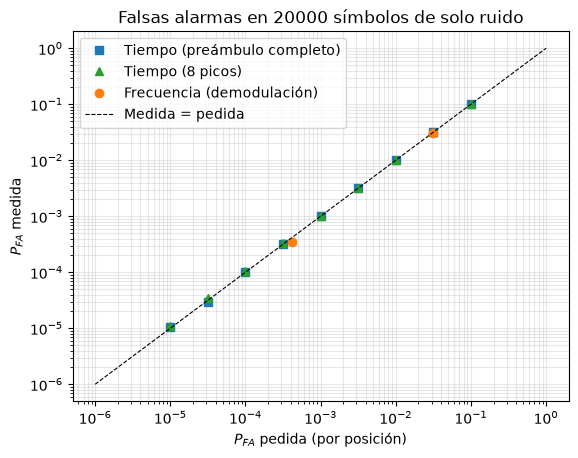

In [42]:
# El anexo no depende de la secuencia aleatoria de los capítulos anteriores
rng = np.random.default_rng(0)
n_simbolos_ruido = 20000
P_FA_pedidas = np.logspace(-1, -5, 9)  # Por posición, para los métodos en el tiempo

falsas_alarmas = falsas_alarmas_medidas(SF, B, n_simbolos_ruido, P_FA_pedidas)
graficar_falsas_alarmas(falsas_alarmas, n_simbolos_ruido);

**Observaciones**:
- Los métodos en el tiempo cumplen la $P_{FA}$ pedida, con menos de 10 % de diferencia hasta $10^{-4}$ por posición, y la demodulación del preámbulo la cumple con $K = 1$. Esto valida las distribuciones bajo $H_0$ (exponencial, Erlang y binomial) y respalda usar la $P_{FA}$ teórica en el punto de operación y en la ROC.
- En $10^{-5}$, y en frecuencia con $K = 2$, la medición se dispersa (entre 0.7 y 2.4 veces la pedida), porque se apoya en pocas falsas alarmas, $\approx 50$ y $\approx 8$ esperadas, que además llegan agrupadas. En el tiempo la plantilla se repite cada $2^{SF}/2$ muestras, así que una falsa alarma suele repetirse medio símbolo después, y en frecuencia cada ventana decidida como símbolo 0 cuenta en las 8 posiciones que la incluyen.

## Anexo B: prueba en el SDR

### Transmisión y recepción de las tramas

**Transmisión**: cada trama mide $F = 5184$ muestras, el preámbulo de 10.25 símbolos y 10 símbolos de *payload*, y la precede un silencio de 5 a 10 símbolos (1280 a 2560 muestras) sin redondear a símbolos enteros. El TX repite sin pausa un buffer de 50 o 200 tramas, de largo par, porque con un largo impar el TX del Pluto agrega una muestra en cada repetición y las tramas siguientes llegan corridas. El RX entrega las muestras en bloques que pasan por una cola, así que después de cambiar la señal transmitida se descartan los primeros bloques, que todavía tienen la señal anterior.

**Largo de la captura**: la captura empieza en un punto cualquiera del buffer, porque depende de la demora de la red y del equipo. Por eso tiene el largo del buffer más el de tres tramas con el silencio más largo. Las dos primeras dan lugar a que el receptor encuentre un silencio y el primer preámbulo, y las tramas que empiezan ahí no se cuentan. Después hay un buffer completo, en el que cada trama empieza exactamente una vez, y la tercera deja lugar para que la última termine dentro de la captura.

**Receptor**: recorre la captura con una ventana de $2F$ muestras, como si las muestras le llegaran de a poco. La primera ventana empieza en el símbolo de menor energía, que con SNR alto cae en un silencio, porque si empezara en la mitad de un *payload* podría confundir sus *chirps* con los del preámbulo. En cada ventana busca un preámbulo con el detector. Si lo encuentra, guarda el inicio y la ventana siguiente empieza donde termina esa trama, y si no, la ventana avanza $F$ muestras. Así cada trama entra entera en alguna ventana, porque una trama que empieza en las primeras $F$ muestras de una ventana termina dentro de ella, y una que empieza en las últimas $F$ queda en las primeras $F$ de la ventana siguiente.

### Fondo de escala del ADC

El ADC del Pluto representa cada muestra de I y de Q con 12 bits, entre $-2048$ y $2047$. El mayor valor es el fondo de escala, y los niveles se expresan en dB respecto de él. El ruido de cuantización tiene una potencia fija, así que la relación señal-ruido de cuantización (SQNR) depende del nivel de la señal. Con un tono que llega justo al fondo de escala, un ADC de $N$ bits tiene

$$
SQNR \approx 6.02\,N + 1.76 \text{ dB} \approx 74 \text{ dB} \quad (N = 12)
$$

y cada dB que la señal queda por debajo del fondo de escala es un dB menos de SQNR. Si la señal supera el fondo de escala, el ADC la recorta.

La ganancia del RX la elige el AGC en el modo *slow attack*, pensado para señales continuas como la del TX cíclico, que corrige la ganancia de a poco según la potencia promedio. El AGC no lleva el pico de la señal al fondo de escala, sino que deja un margen para los picos. Con SNR negativo la señal recibida es casi toda ruido gaussiano, con picos de varias veces su desvío estándar.

Para ver cuánto del rango usa la señal se transmite un tono, una exponencial compleja de $\approx 125$ kHz, cuyo pico coincide con su valor eficaz porque su amplitud es constante. Se captura con la ganancia que eligió el AGC, con 20 dB menos y con 16 dB más. Se espera:
- **Con la ganancia del AGC**: un círculo en el plano I/Q. Una elipse indicaría que I y Q tienen distinta ganancia o no están exactamente a 90°. En el espectro aparecen el tono, su imagen en $-125$ kHz, causada por ese mismo desbalance, y la fuga del oscilador local en 0 Hz.
- **Con 20 dB menos**: el tono usa menos niveles del ADC. Si el ruido fuera solo el de cuantización, que no depende de la ganancia, el SNR bajaría lo mismo que la ganancia.
- **Con 16 dB más**: I y Q se recortan, el círculo se vuelve un cuadrado y aparecen armónicos del tono.

In [ ]:
# Tono de ~125 kHz con un número entero de ciclos en el buffer, para que el TX cíclico no tenga
# saltos. K_TONO impar: el error de cuantización no se repite cada pocas muestras
N_TONO, K_TONO = 2**14, 2**11 + 1
DESVIOS_GANANCIA_dB = np.array([0, -20, 16])  # Respecto de la ganancia del AGC
tono = np.exp(2j * np.pi * K_TONO * np.arange(N_TONO) / N_TONO)


"""
Captura el tono con la ganancia que elige el AGC y con dos ganancias más.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        Las capturas y las ganancias del RX.
"""

def medir_tono(pluto):

    _, ganancia_agc = grabar(pluto, tono, N_TONO)  # El AGC elige la ganancia
    ganancias = np.clip(ganancia_agc + DESVIOS_GANANCIA_dB, 0, 70)  # Rango de ganancia del RX
    capturas = []
    for ganancia in ganancias:
        pluto.rx_hardwaregain_chan0 = float(ganancia)
        capturas.append(grabar(pluto, tono, N_TONO, calibrar=False)[0])
    return np.array(capturas), {"gains_dB": ganancias}


"""
Grafica el espectro y el plano I/Q de cada captura del tono.

    Parámetros:
        capturas: Capturas del tono, una por fila.
        ganancias_dB: Ganancia del RX de cada captura.
        k: Bin del tono en la FFT.
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        La figura.
"""

def graficar_tono_sdr(capturas: np.ndarray, ganancias_dB: np.ndarray, k: int, B: float):

    # Capturas de un tono en el bin k de la FFT con distintas ganancias del RX, una por fila:
    # espectro y plano I/Q contra el fondo de escala del ADC
    fig, axes = plt.subplots(
        len(capturas), 2, figsize=(11, 3.6 * len(capturas)), width_ratios=[2.5, 1], squeeze=False
    )
    cuadrado = FONDO_DE_ESCALA_ADC * np.array([-1, 1, 1, -1, -1])
    for r, ganancia, (ax_f, ax_iq) in zip(capturas, ganancias_dB, axes):
        X = np.abs(np.fft.fftshift(np.fft.fft(r))) / r.size / FONDO_DE_ESCALA_ADC
        X_dB = 20 * np.log10(X + 1e-12)
        f = np.fft.fftshift(np.fft.fftfreq(r.size, 1 / B)) / 1e3
        ax_f.plot(f, X_dB, color="gray", lw=0.6)
        marcas = [(k, "Tono", "o"), (-k, "Imagen", "s"), (0, "Fuga del LO", "^")]
        for bin_, nombre, marcador in marcas:
            i = r.size // 2 + bin_  # Índice después de fftshift
            ax_f.plot(f[i], X_dB[i], marcador, label=f"{nombre}: {X_dB[i]:.0f} dB")
        ax_f.set(
            title=f"Espectro con ganancia {ganancia:.0f} dB",
            xlabel="Frecuencia [kHz]",
            ylabel="dB respecto del fondo de escala",
            ylim=(-140, 10),
        )
        ax_f.grid(True)
        ax_f.legend(loc="upper left", fontsize="small")

        ax_iq.plot(np.real(r), np.imag(r), ",", alpha=0.5)
        ax_iq.plot(cuadrado, np.roll(cuadrado, 1), "r--", lw=0.8, label="Fondo de escala")
        ax_iq.set(title="Plano I/Q", xlabel="I", ylabel="Q", aspect="equal")
        ax_iq.legend(loc="upper right", fontsize="small")
    fig.tight_layout()
    return fig


c_tono, meta_tono = adquirir("captures/tone.npz", medir_tono, B_sdr, URI)
for r, ganancia in zip(c_tono, meta_tono["gains_dB"]):
    P = np.abs(np.fft.fft(r)) ** 2  # Tono en K_TONO, imagen en -K_TONO y fuga del LO en 0
    snr_tono_dB = 10 * np.log10(P[K_TONO] / (P.sum() - P[K_TONO] - P[-K_TONO] - P[0]))
    nivel_dB = 10 * np.log10(potencia(r) / FONDO_DE_ESCALA_ADC**2)
    print(
        f"Ganancia {ganancia:2.0f} dB: nivel {nivel_dB:5.1f} dB respecto del fondo de escala, "
        f"pico {pico_adc(r) / FONDO_DE_ESCALA_ADC:4.0%}, SNR del tono {snr_tono_dB:3.0f} dB"
    )
graficar_tono_sdr(c_tono, meta_tono["gains_dB"], K_TONO, B_sdr);

**Observaciones**:
- Con la ganancia del AGC (9 dB) el tono queda a $-11.7$ dB del fondo de escala, con el pico en el 26 % del rango. El AGC deja $\approx 12$ dB de margen para los picos.
- El plano I/Q es un círculo. La imagen queda 65 dB debajo del tono y la fuga del oscilador local, 76 dB debajo, así que el desbalance entre I y Q y la fuga no afectan al receptor.
- El SNR del tono es de 52 dB, menos que los $\approx 62$ dB de SQNR que corresponden a ese nivel ($74 - 11.7$). La captura con menos ganancia quedó en el mínimo del RX, 0 dB, 9 dB menos que el AGC, y su SNR bajó solo 5 dB. El ruido que domina no es el de cuantización sino el analógico del RX, que la ganancia amplifica junto con el tono.
- Con 16 dB más (25 dB) I y Q se recortan, el círculo se vuelve un cuadrado, aparecen armónicos del tono (el mayor en $-375$ kHz) y la imagen sube a $-26$ dB. El SNR cae a 15 dB.